# Undertow DeepSea & False Beacon Frozen Lake
### Why more exploration can buy the wrong evidence

**Read the maps first.** A route can reach a dock, collect observations, and still fail to reveal that another route is better. These benchmarks separate **reward**, **coverage**, and **decision-relevant evidence**.

This walkthrough contains kernel-generated route illustrations, exact finite-model checks, and verified cached learning curves. Its default execution launches **no training**, downloads nothing, and needs no raw study folder.

**Setup must happen before launching the kernel.** From the repository root, in a terminal:

```bash
python3 -m venv .venv
source .venv/bin/activate
python -m pip install -e '.[notebook]'
python -m ipykernel install --sys-prefix --name ceac-undertow --display-name "Python (CEAC)"
python -m jupyter lab notebooks/Undertow_FalseBeacon.ipynb
```

Choose **Python (CEAC)**. In VS Code, select this repository's `.venv/bin/python`. Python 3.10 or newer is required; `ipykernel` is included in the notebook extra. Do not use the archived `legacy/inforatio` installer.

The saved outputs are also readable directly on GitHub.
The [complete PDF report](evidence/report.pdf) contains all seven methods, both Bayesian prior treatments, and the scientific audits.


In [1]:
from pathlib import Path
import sys, importlib.util

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "pyproject.toml").is_file() and (p / "ceac/model.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook inside the cloned CEAC repository.")
if sys.version_info < (3, 10):
    raise RuntimeError("Select the CEAC kernel with Python 3.10 or newer.")
missing = [name for name in ("numpy", "scipy", "matplotlib", "IPython", "ceac", "ceac_walkthrough")
           if importlib.util.find_spec(name) is None]
if missing:
    raise RuntimeError(f"Missing {missing}. In this kernel's environment run: "
                       f"{sys.executable} -m pip install -e '{ROOT}[notebook]'")
import numpy as np
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown
from ceac.model import FiniteModel
from ceac_walkthrough.evidence import verified_bundle
from ceac_walkthrough.visuals import (draw_undertow, draw_false_beacon, draw_signal_laws,
                                     draw_policy_facts)

bundle, provenance = verified_bundle(ROOT / "notebooks")
print(f"Python {sys.version.split()[0]} | verified {provenance['source_runs']} unique source runs")
print(f"Portable export: {provenance['curve_runs']} per-seed learning traces; no raw-cache dependency.")
from ceac.pathology_report import (strength_groups, draw_method_overlay,
                                   draw_strength_learning, draw_strength_diagnostics,
                                   draw_pathology_response, draw_ceac_advantage, draw_endpoint_comparison,
                                   ceac_comparison_section, ceac_advantage_statistics)
groups = strength_groups(bundle["curves"])
MODE = 1  # Set to 0 for the stationary normal-mode control; no retraining.
print("Matched physical-strength preflight:", bundle["strength_checks"])


Python 3.11.13 | verified 336 unique source runs
Portable export: 336 per-seed learning traces; no raw-cache dependency.
Matched physical-strength preflight: [{'context': 0, 'environment': 'deepsea', 'fixed_domain': True, 'fixed_optimum': True, 'fixed_return_range': True, 'fixed_useful_route_values_and_KL': True, 'strengths': [0.05, 0.25, 0.5, 0.75]}, {'context': 0, 'environment': 'frozenlake', 'fixed_domain': True, 'fixed_optimum': True, 'fixed_return_range': True, 'fixed_useful_route_values_and_KL': True, 'strengths': [0.05, 0.25, 0.5, 0.75]}]


## 1. Undertow: the horizon is a navigation budget

**Blue reaches the goal. Magenta generates observations while losing the ability to reach it.** Every rightward move spends one depth unit and gains one column. The nuisance action spends depth without gaining a column. Its random symbols have the same law in both candidate modes.

The gate offers a different choice: a small-cost probe reveals a mode-sensitive bit. A challenge follows the ordinary route geometry but has a mode-dependent payoff. The map below is generated by actual `reset`/`step` calls; it is an illustrative trajectory, not a trained-policy success statistic.

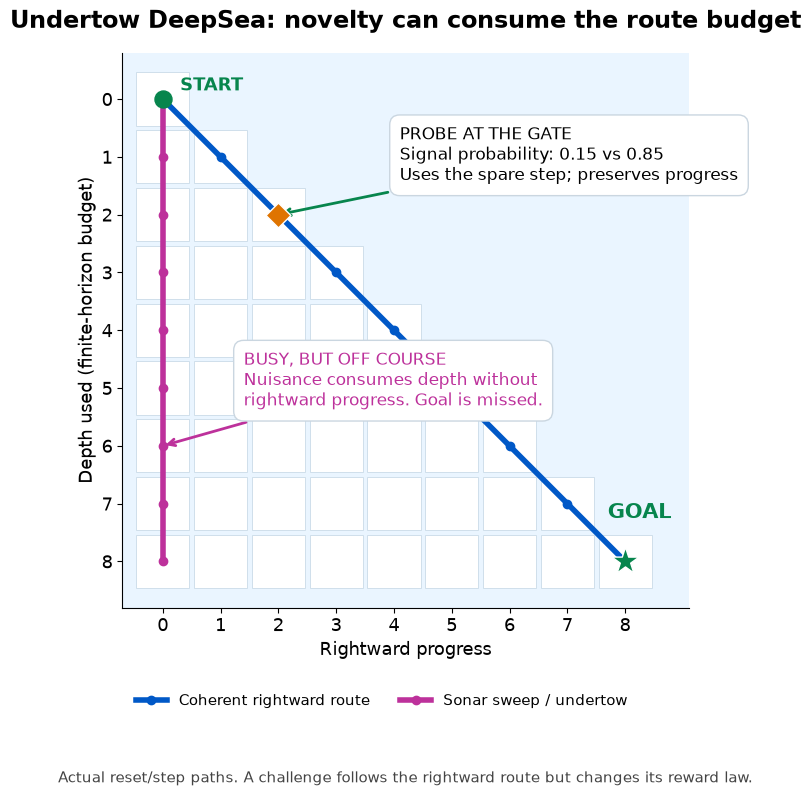

In [2]:
fig = draw_undertow()
plt.show()

## 2. False Beacon: a successful route can leave the decision unresolved

**The inner route has the same trajectory law in both modes; the outer route becomes better in mode 1.** Repeating the inner route therefore cannot detect this opportunity.

The noisy reeds are a false beacon: they offer more observable variety without revealing the mode. The deep survey supplies useful evidence. The shallow survey is also uninformative about the mode. Geometry and paths below come from the environment implementation. Random terminal outcomes mean reaching a dock and obtaining a reward are distinct events.

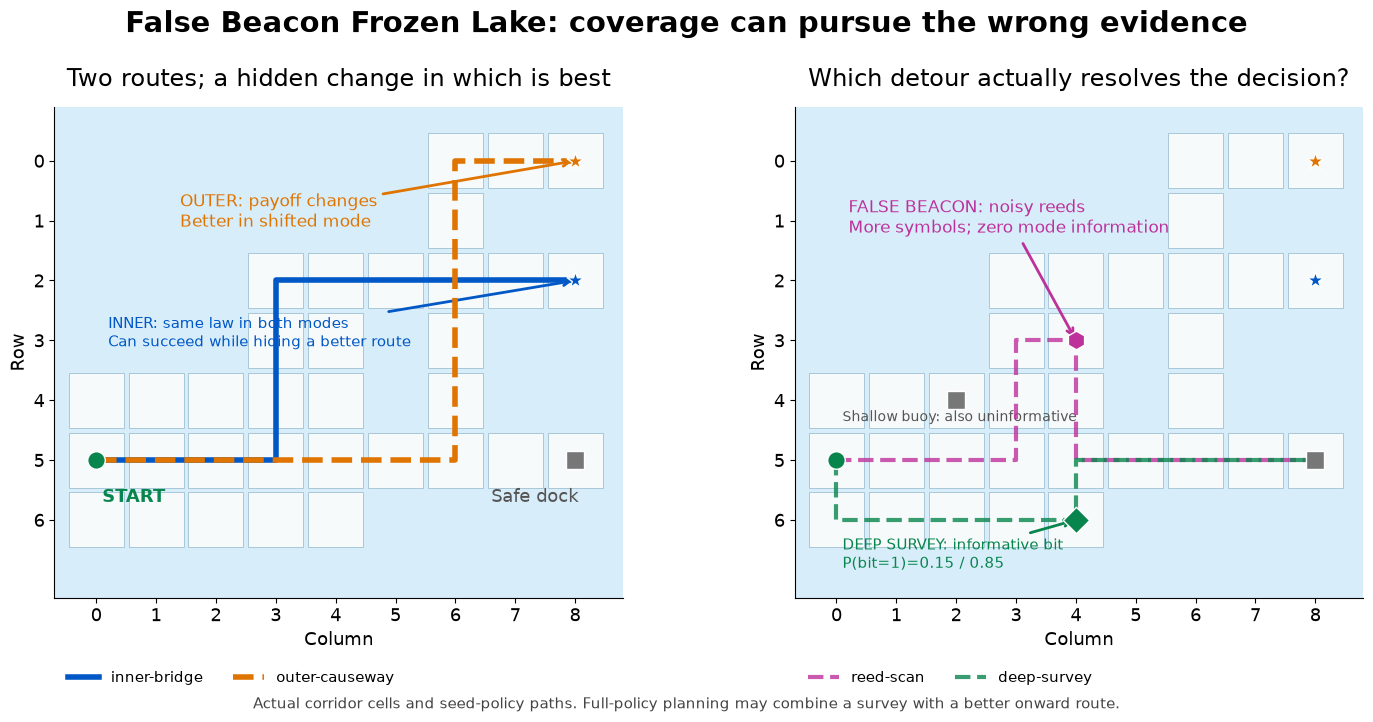

In [3]:
fig = draw_false_beacon()
plt.show()

## 3. What makes an observation useful?

The relevant quantity is a likelihood ratio against a **policy-changing** alternative, not the number of distinct symbols. If both modes emit a symbol with probability $1/M$, its log likelihood ratio is zero even though its entropy is $\log M$.

The two-outcome probe is much simpler, but separates Bernoulli(0.15) from Bernoulli(0.85):

$$D_{\mathrm{KL}} = 0.7\log(17/3) \simeq 1.214\ \text{nats}.$$

**A richer observation alphabet can be less useful for the decision.** These charts show declared observation laws, not sampled training histograms.

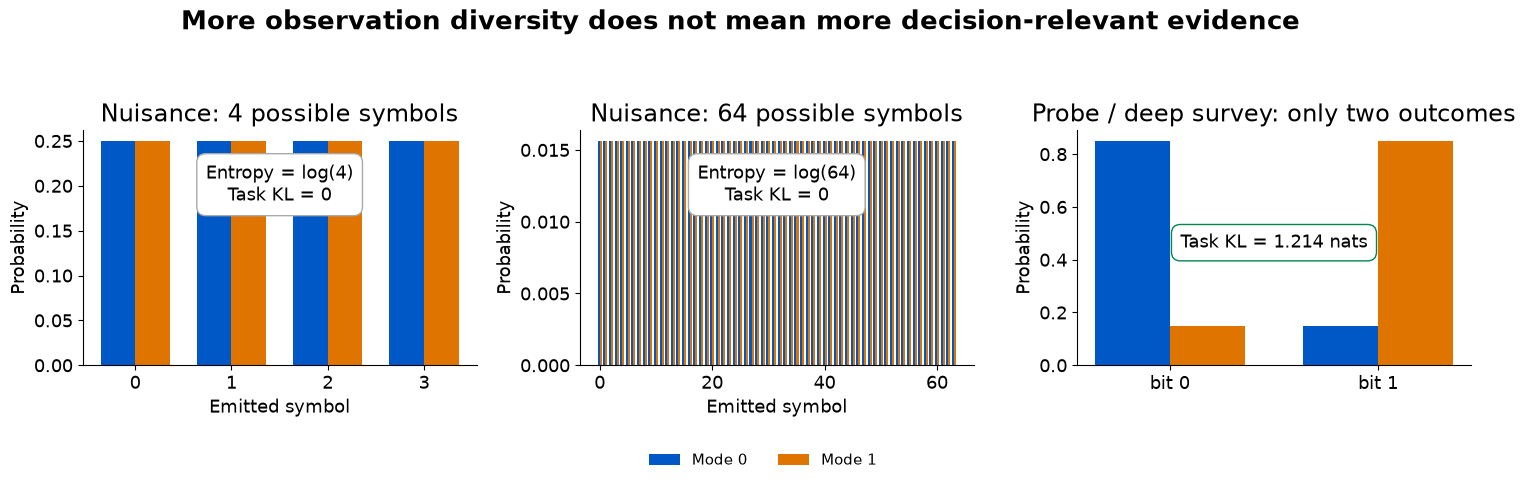

In [4]:
fig = draw_signal_laws()
plt.show()

## 4. Check the pathology against the actual finite models

We now compile both candidate laws from each environment's `step()` behavior at **weak signal, M=4**, and evaluate the seed policies exactly. This is diagnostic planning, not self-play training.

The assertions require: (i) the old route is observationally identical across modes, (ii) it becomes suboptimal in mode 1, (iii) the nuisance policy has zero task KL, and (iv) the probe/survey is informative. The frozen-lake survey shown is the declared seed route; full-policy separation can synthesize a better onward continuation.

Both environments pass the confounding, nuisance and informative-probe checks.


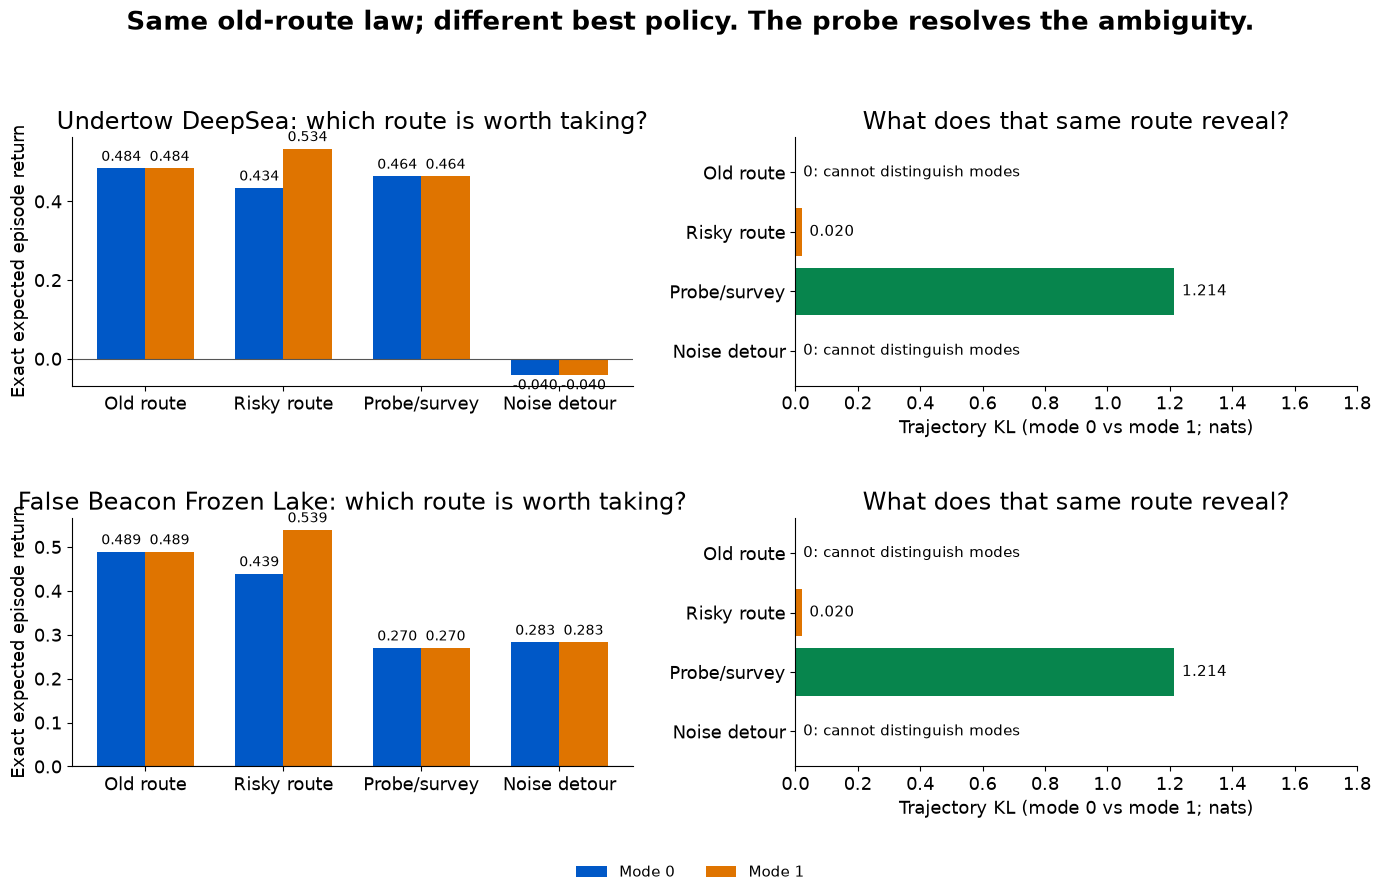

In [5]:
models = {kind: FiniteModel(kind, benchmark="weak_signal_m4")
          for kind in ("deepsea", "frozenlake")}
for kind, model in models.items():
    policies = {p.label: p for p in model.seed_policies()}
    old, noise, probe = (("exploit", "sonar-sweep", "probe") if kind == "deepsea"
                         else ("inner-bridge", "reed-scan", "deep-survey"))
    values, information = model.evaluate(policies[old])
    np.testing.assert_allclose(information, 0, atol=1e-12)
    np.testing.assert_allclose(values[0], values[1], atol=1e-12)
    assert model.optimal_returns[1] - values[1] > 0.049
    np.testing.assert_allclose(model.evaluate(policies[noise])[1], 0, atol=1e-12)
    assert model.evaluate(policies[probe])[1][0, 1] > 1.2
print("Both environments pass the confounding, nuisance and informative-probe checks.")
fig = draw_policy_facts(models)
plt.show()

## 5. Does stronger pathology make exploration more costly?

**Read across each environment's row.** The first panel shows total exploration cost; the second isolates the extra cost caused by increasing the recorded nuisance parameter relative to its mildest setting; the third shows the policy's remaining value gap. The horizontal axis is now pathology strength, rather than training time. All seven methods remain visible in the legend and comparisons, including both Bayesian priors.

The middle panel pairs the same seed across doses **before** calculating variation. A large total regret at every dose is different from deterioration as the dose increases. The linear middle panels retain negative changes. The total-regret panel uses a labeled symlog axis to show CEAC and Bayesian IDS alongside much larger costs.

**What was actually swept:** Undertow loses progress with probability $\rho$. False Beacon adds **one dwell step** with probability $\rho$; its physical breadth, nuisance alphabet and horizon stay fixed. The current data cannot demonstrate a breadth-dependent failure. Curves connect measured doses, with no monotonic fit. Shading shows sample SD over three seeds, not confidence intervals.

The second figure directly compares each alternative with CEAC: **comparator regret minus CEAC regret**. Positive values favor CEAC; negative values favor the comparator. Bold cells mean that every recorded paired seed favored CEAC, not statistical significance. The generated table also reports whether CEAC's advantage grows above its mild-dose advantage. Endpoint value ties are reported separately from exploration cost.

Use the earlier `MODE` setting to inspect mode 0 as well as mode 1. The standard report includes both; these are stationary modes, not hidden changes within an episode sequence.


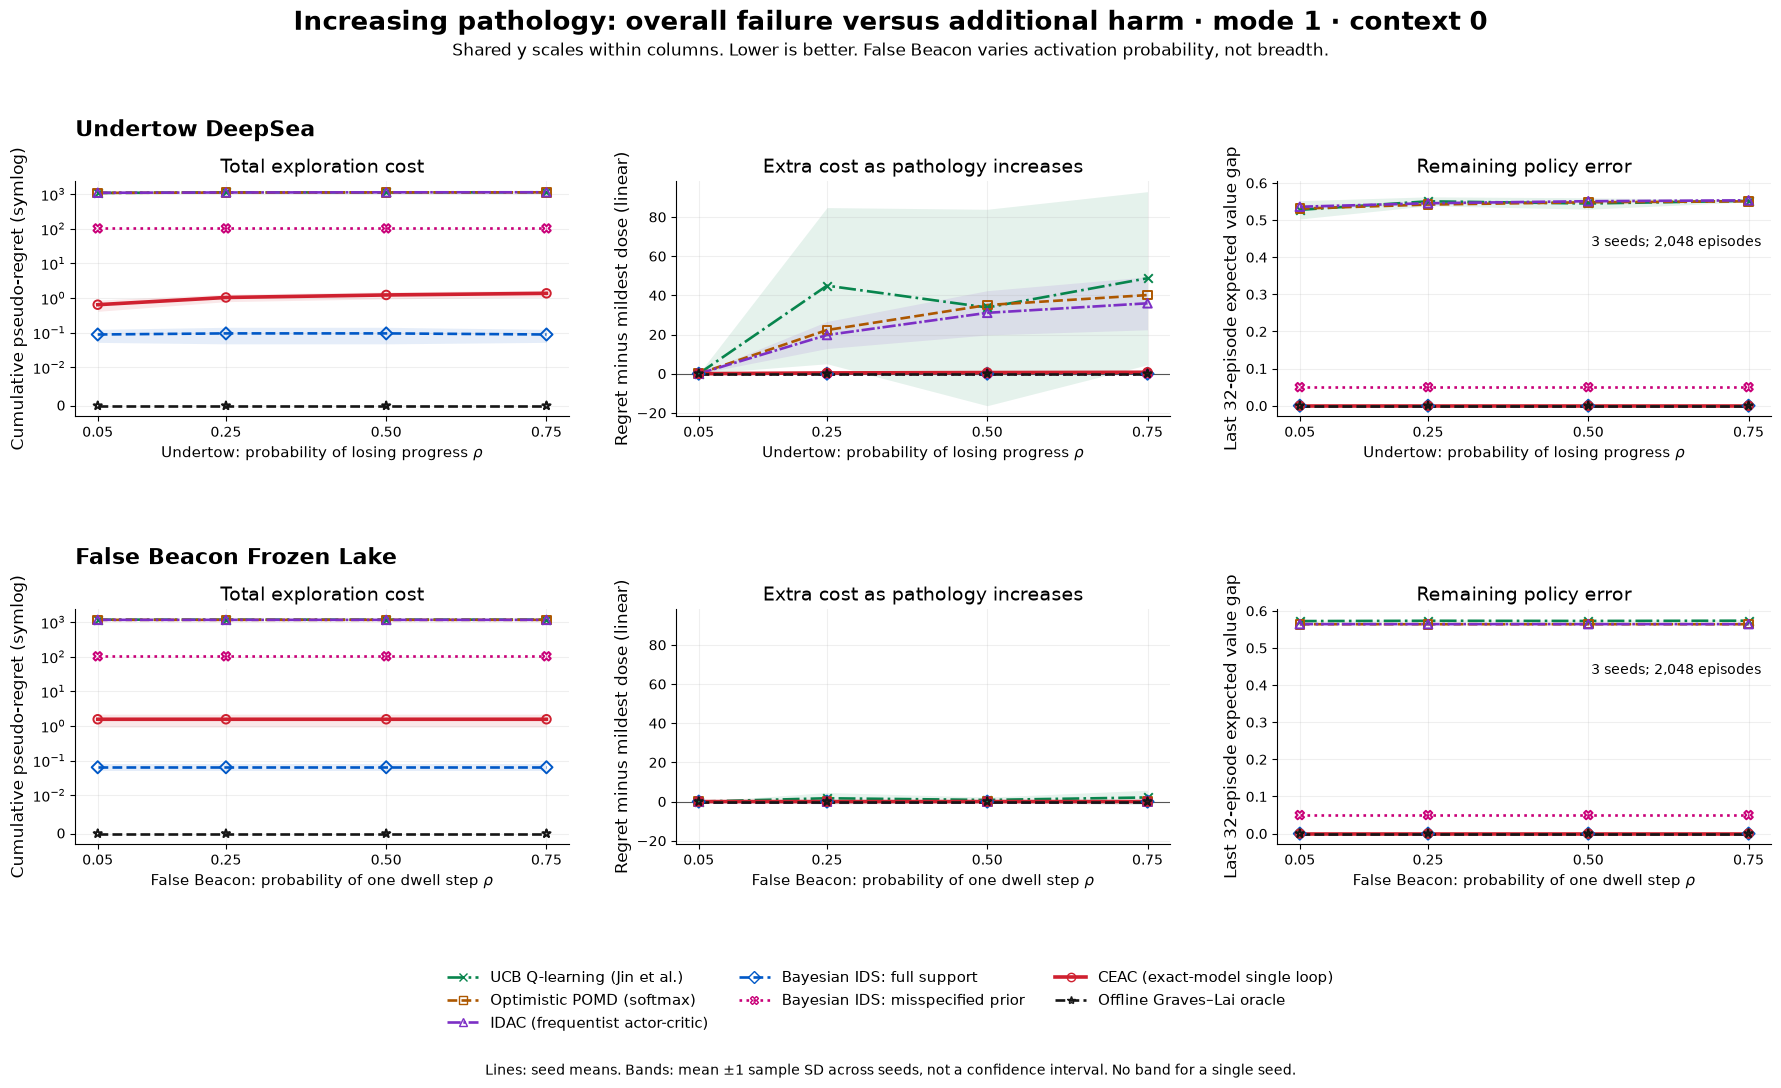

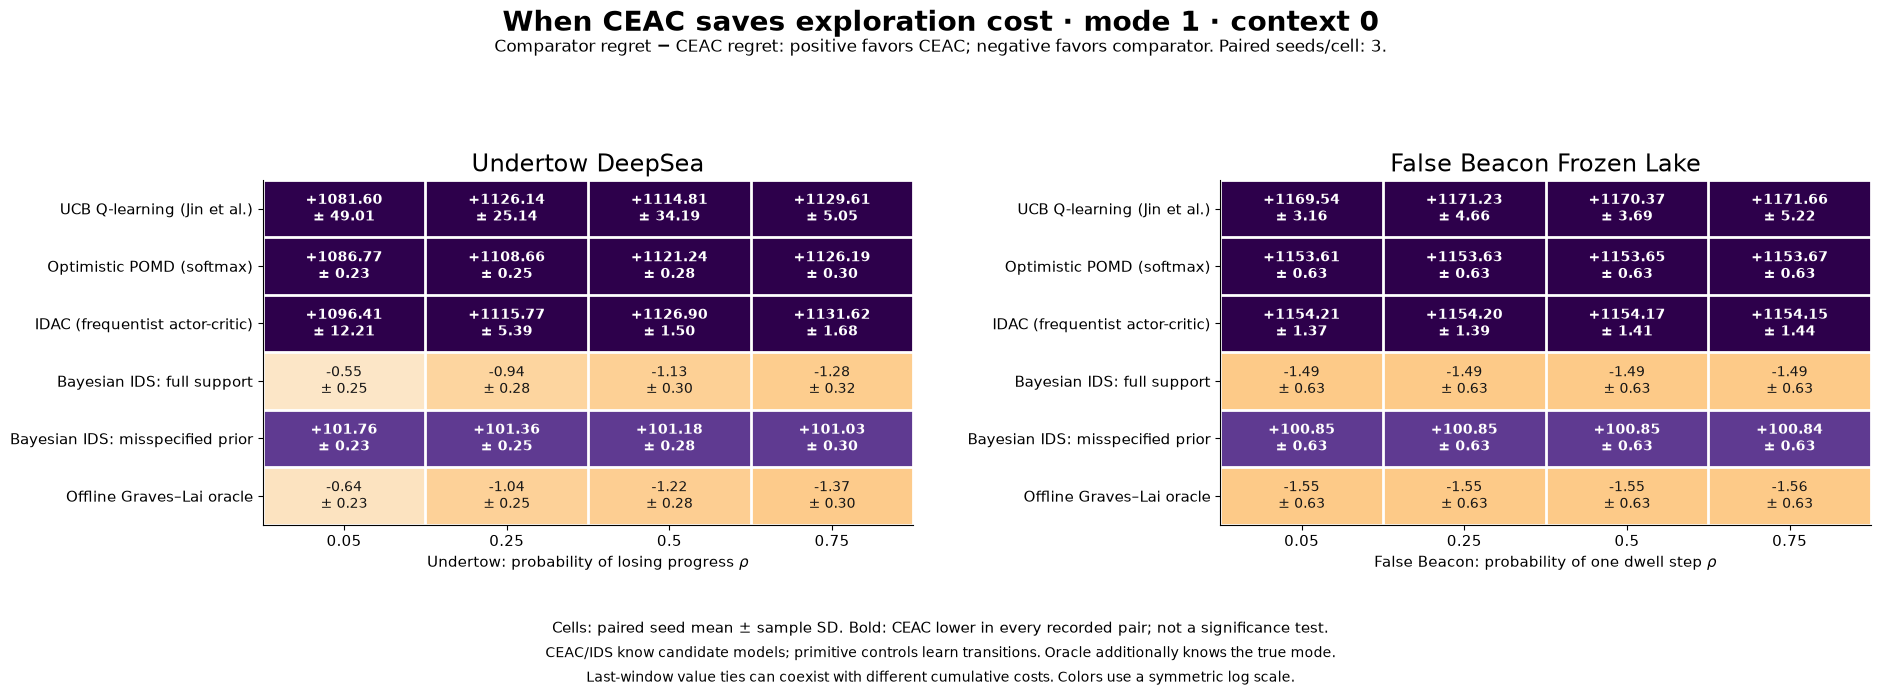

## Where CEAC performs better

Positive saved regret means comparator minus CEAC. The additional advantage subtracts the same contrast at the mildest dose, within each seed. It separates an advantage already present at mild pathology from one that grows with pathology. All uncertainties below are sample SD across paired seeds, not confidence intervals. Bold entries favor CEAC in every recorded pair; this is descriptive, not a significance test.

False Beacon currently varies the probability of one dwell step, not beacon breadth. The full-support and excluded-support Bayesian treatments remain distinct. CEAC/IDS have candidate-model access; the primitive controls learn from transitions. These are finite-budget comparisons, not evidence that a learned evidence critic caused the advantage.

### Undertow DeepSea · mode 1 · context 0

CEAC cumulative regret: 0.641 at rho=0.05 to 1.365 at rho=0.75; strongest-dose last-window value gap: 0.0000.

Full-support IDS has lower cumulative regret (0.088) at the strongest dose; its last-window value gap is 0.0000.

Strongest-dose comparison (rho=0.75); positive numbers favor CEAC.

| Comparator | Regret saved | Additional advantage over mild dose | Last value-gap reduction | Pairs: CEAC lower / tied / higher regret |
|---|---:|---:|---:|---:|
| UCB Q-learning (Jin et al.) | **+1129.61 ± 5.05** | +48.02 ± 44.15 | **+0.5520 ± 0.0031** | 3 / 0 / 0 |
| Optimistic POMD (softmax) | **+1126.19 ± 0.30** | **+39.42 ± 0.07** | **+0.5506 ± 0.0000** | 3 / 0 / 0 |
| IDAC (frequentist actor-critic) | **+1131.62 ± 1.68** | **+35.21 ± 13.56** | **+0.5533 ± 0.0006** | 3 / 0 / 0 |
| Bayesian IDS: full support | -1.28 ± 0.32 | -0.72 ± 0.07 | +0.0000 ± 0.0000 | 0 / 0 / 3 |
| Bayesian IDS: misspecified prior | **+101.03 ± 0.30** | -0.72 ± 0.07 | **+0.0500 ± 0.0000** | 3 / 0 / 0 |
| Offline Graves–Lai oracle | -1.37 ± 0.30 | -0.72 ± 0.07 | +0.0000 ± 0.0000 | 0 / 0 / 3 |

### False Beacon Frozen Lake · mode 1 · context 0

CEAC cumulative regret: 1.554 at rho=0.05 to 1.555 at rho=0.75; strongest-dose last-window value gap: 0.0000.

Full-support IDS has lower cumulative regret (0.064) at the strongest dose; its last-window value gap is 0.0000.

Strongest-dose comparison (rho=0.75); positive numbers favor CEAC.

| Comparator | Regret saved | Additional advantage over mild dose | Last value-gap reduction | Pairs: CEAC lower / tied / higher regret |
|---|---:|---:|---:|---:|
| UCB Q-learning (Jin et al.) | **+1171.66 ± 5.22** | +2.12 ± 3.67 | **+0.5735 ± 0.0031** | 3 / 0 / 0 |
| Optimistic POMD (softmax) | **+1153.67 ± 0.63** | **+0.06 ± 0.00** | **+0.5641 ± 0.0000** | 3 / 0 / 0 |
| IDAC (frequentist actor-critic) | **+1154.15 ± 1.44** | -0.05 ± 0.17 | **+0.5643 ± 0.0008** | 3 / 0 / 0 |
| Bayesian IDS: full support | -1.49 ± 0.63 | -0.00 ± 0.00 | +0.0000 ± 0.0000 | 0 / 0 / 3 |
| Bayesian IDS: misspecified prior | **+100.84 ± 0.63** | -0.00 ± 0.00 | **+0.0500 ± 0.0000** | 3 / 0 / 0 |
| Offline Graves–Lai oracle | -1.56 ± 0.63 | -0.00 ± 0.00 | +0.0000 ± 0.0000 | 0 / 0 / 3 |


In [6]:
rows = bundle["pathology_statistics"]
assert ceac_advantage_statistics(rows) == bundle["ceac_comparisons"]["rows"]
fig = draw_pathology_response(rows, mode=MODE)
plt.show()
fig = draw_ceac_advantage(rows, mode=MODE)
plt.show()
display(Markdown("\n".join(ceac_comparison_section(rows, context=0, mode=MODE))))


## 6. Overlay optimism, frequentist IDAC and Bayesian IDS

The saved sweep has **four physical diversion probabilities**, two environments, two stationary modes, three seeds, and **2,048 training episodes per cell**. Each panel overlays the actual runs of:

- UCB-Hoeffding Q-learning (greedy actions).
- Optimistic POMD (softmax mirror descent).
- IDAC (frequentist cost/occupancy-entropy actor-critic).
- Bayesian IDS with full support: $p_0=(0.5,0.5)$.
- Bayesian IDS with a misspecified prior: $p_0=(1,0)$, excluding mode 1.
  Mode 1 is the misspecification test; mode 0 is the correctly specified negative control.
- CEAC (exact-model single loop) and the offline Graves–Lai oracle.

**IDAC and Bayesian IDS have different objectives.** IDAC optimizes a cost-to-occupancy-entropy ratio; Bayesian IDS uses posterior regret and information about the task model. They are not interchangeable versions of one estimator.

**All seven methods appear for both environments**, including both Bayesian treatments (48 completed runs each). Full-support IDS is blue; misspecified-prior IDS is fuchsia. Color identifies the method and remains fixed across panels. The symlog regret axis shows both large exploration costs and small residual costs; the method panels below also use a shared symlog axis, linear within ±0.01. Shading is **mean ±1 sample SD across seeds**, not a confidence interval. CEAC/IDS have candidate-model access; the primitive learners receive the public domain, reward bounds and observed transitions.

These are the same rendering functions called by the standard report command, not separate notebook plots.


**Coincident curves are real ties, not missing runs.** Hollow markers sit above all curves at staggered measured episodes. In False Beacon, UCB-Q/POMD/IDAC have nearly equal large costs, while several policies have zero late value gap. The endpoint views give every method its own row and numeric mean ± sample SD, so both exact ties and small differences remain readable. No metric values are offset.


ids: 48 completed runs; initial mode-1 prior = 0.5
ids_zero: 48 completed runs; initial mode-1 prior = 0.0


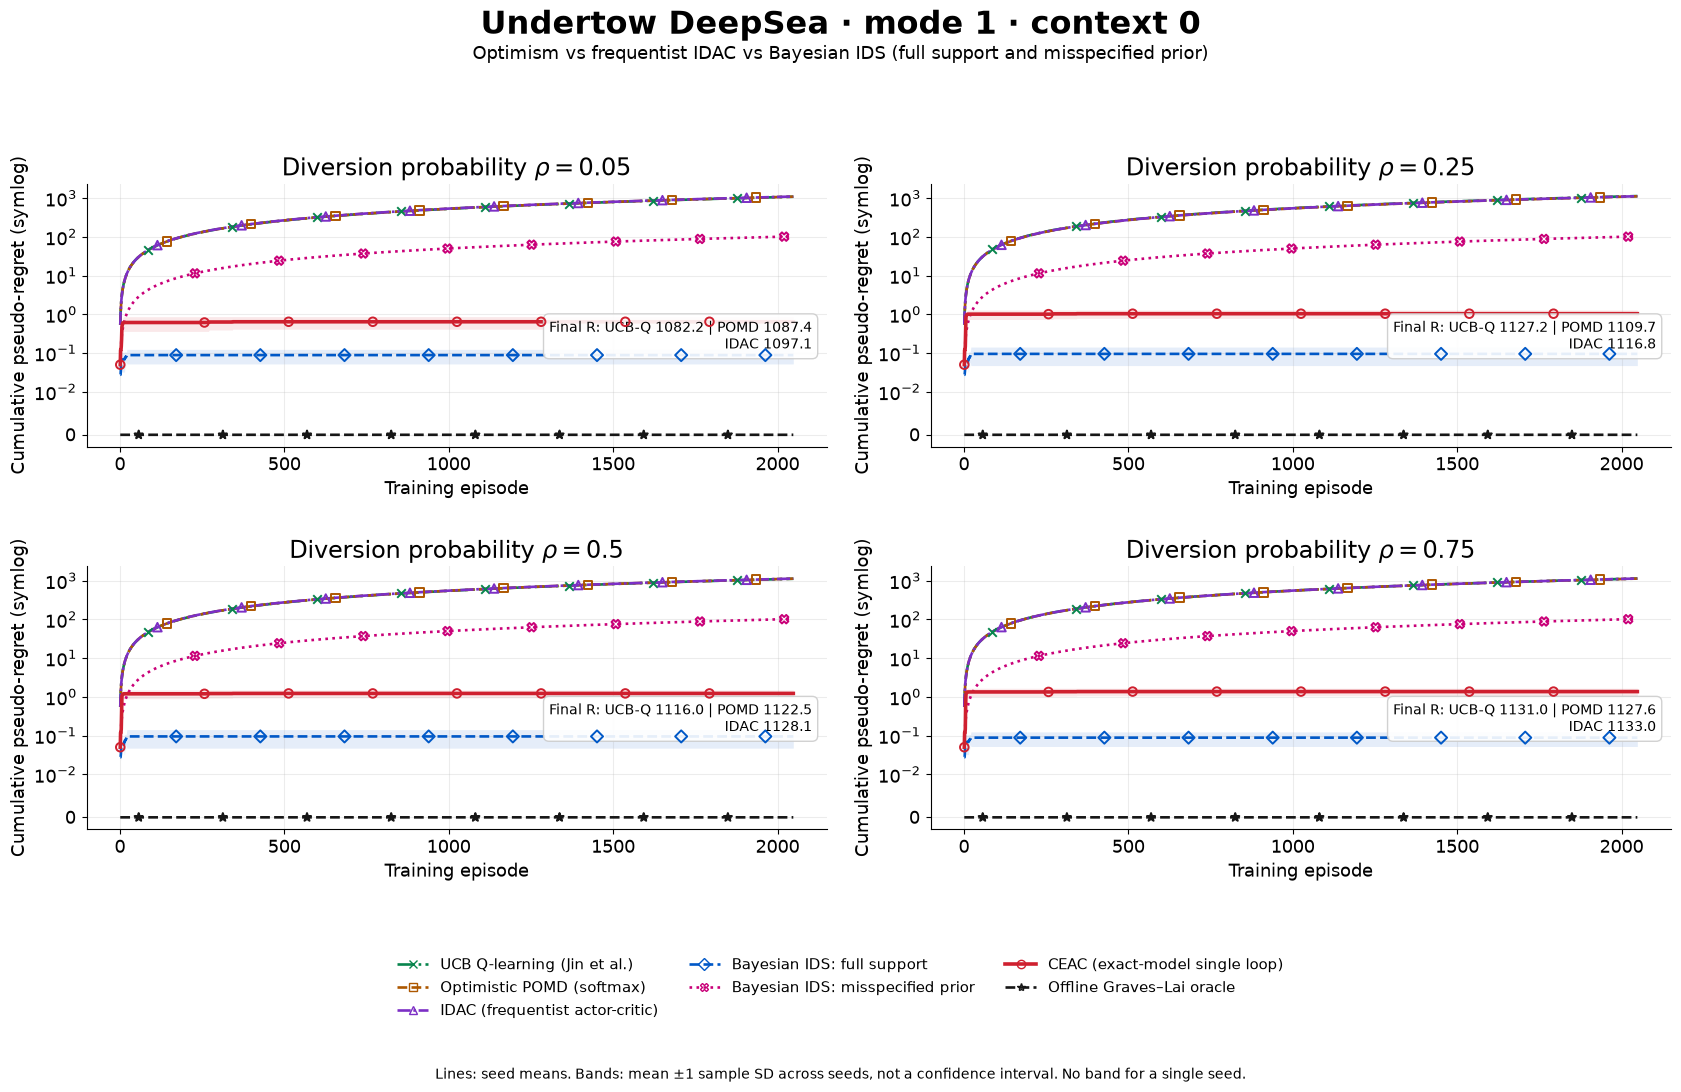

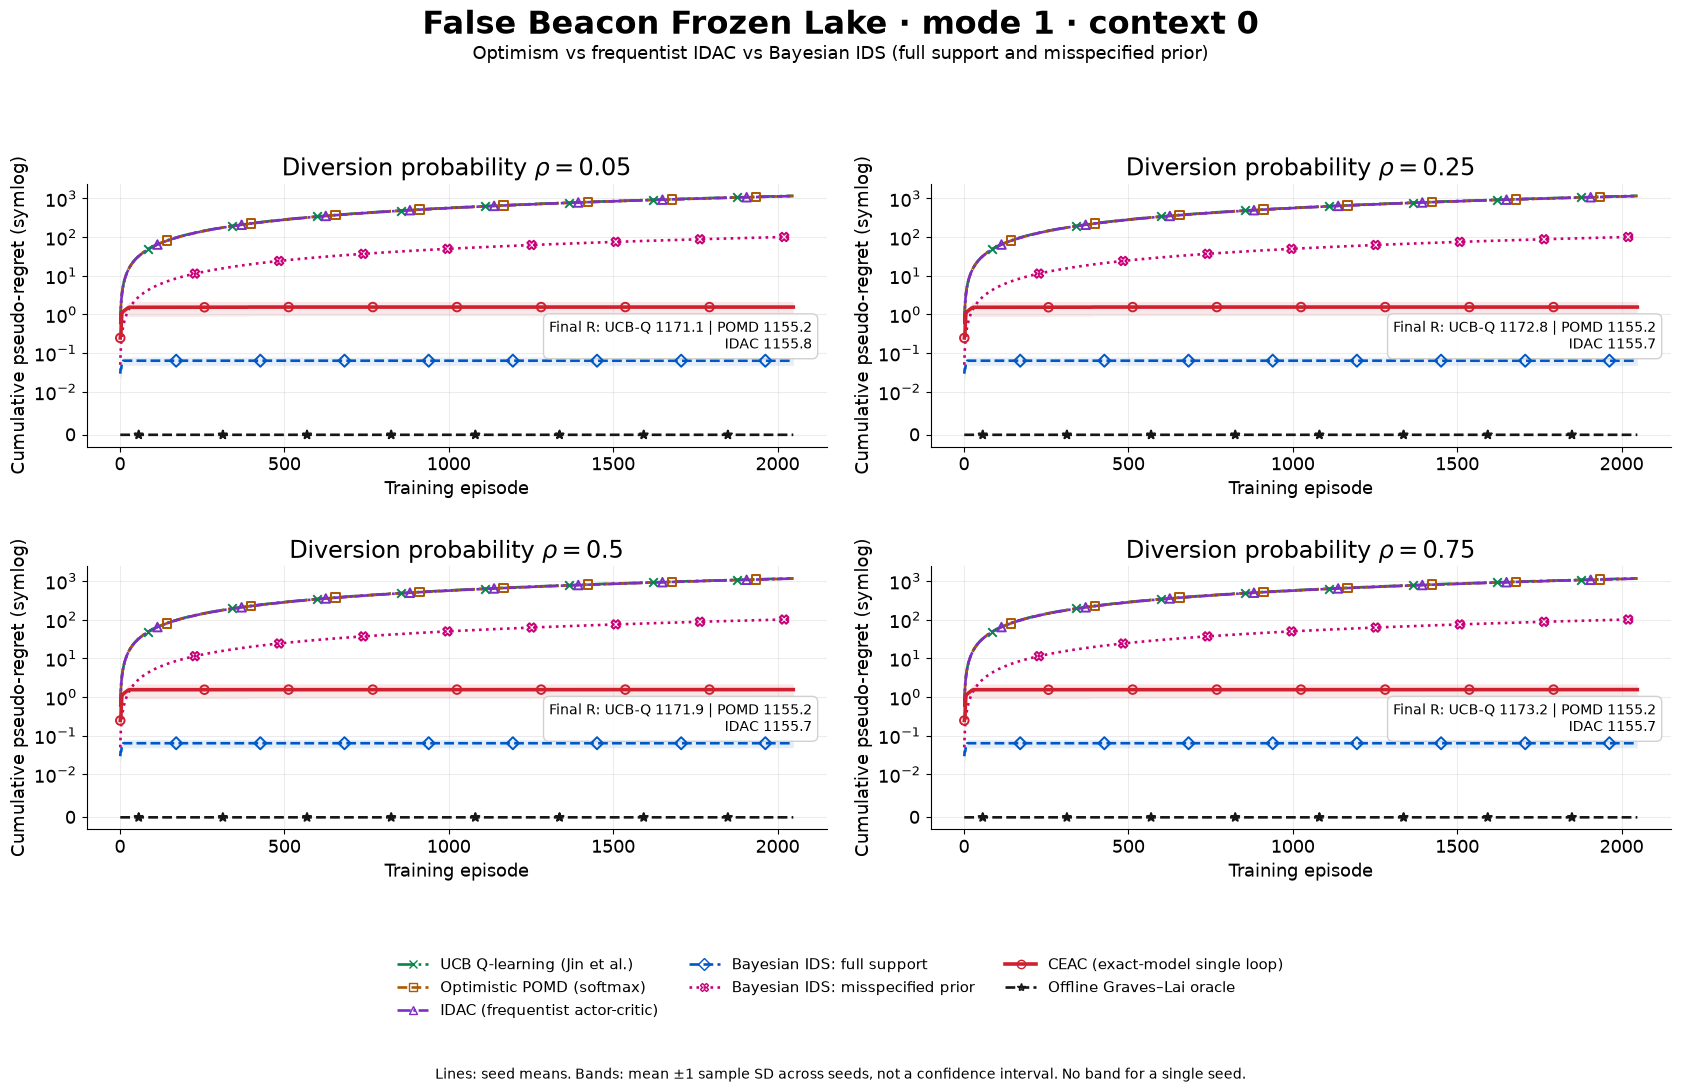

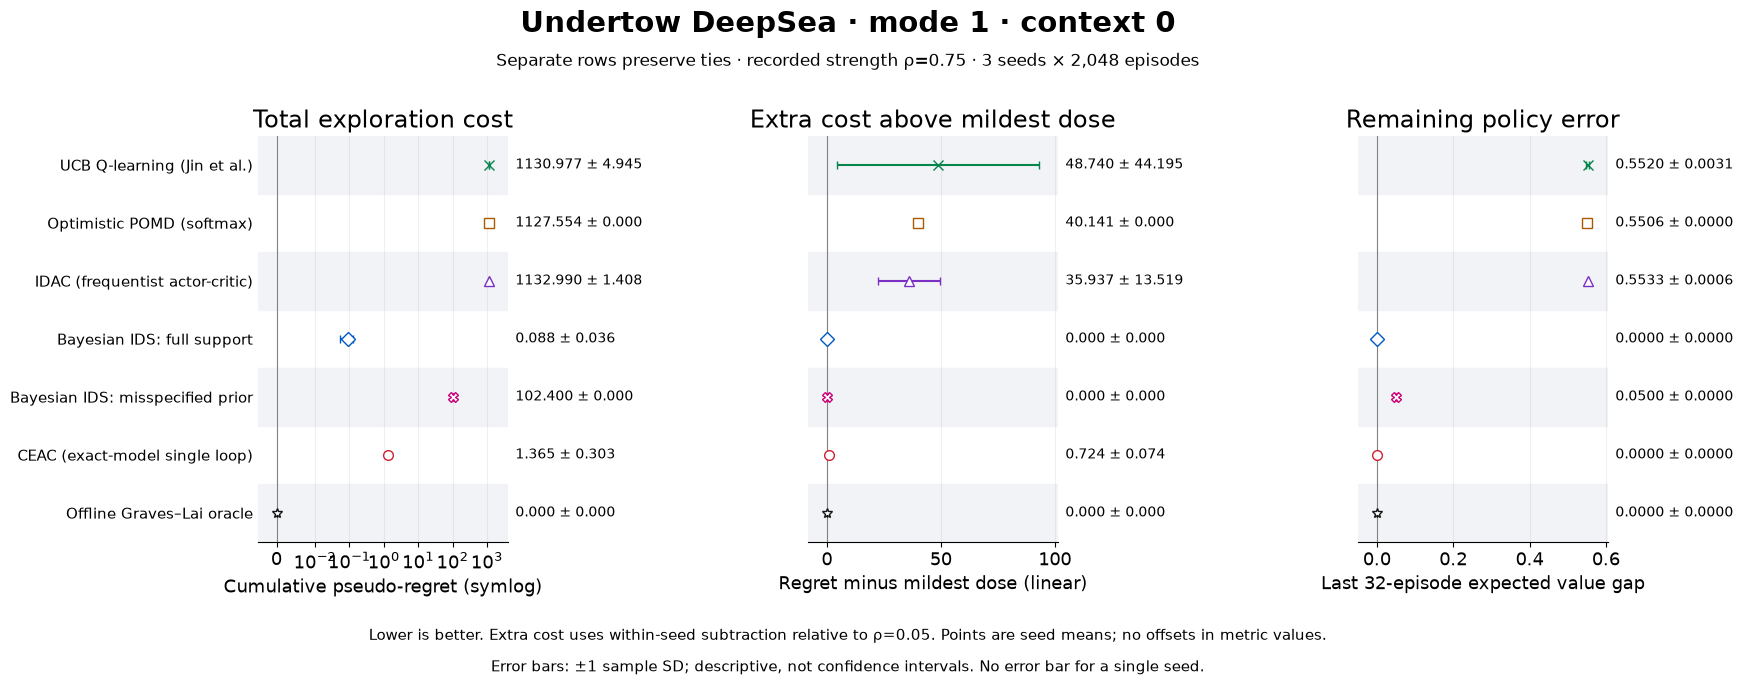

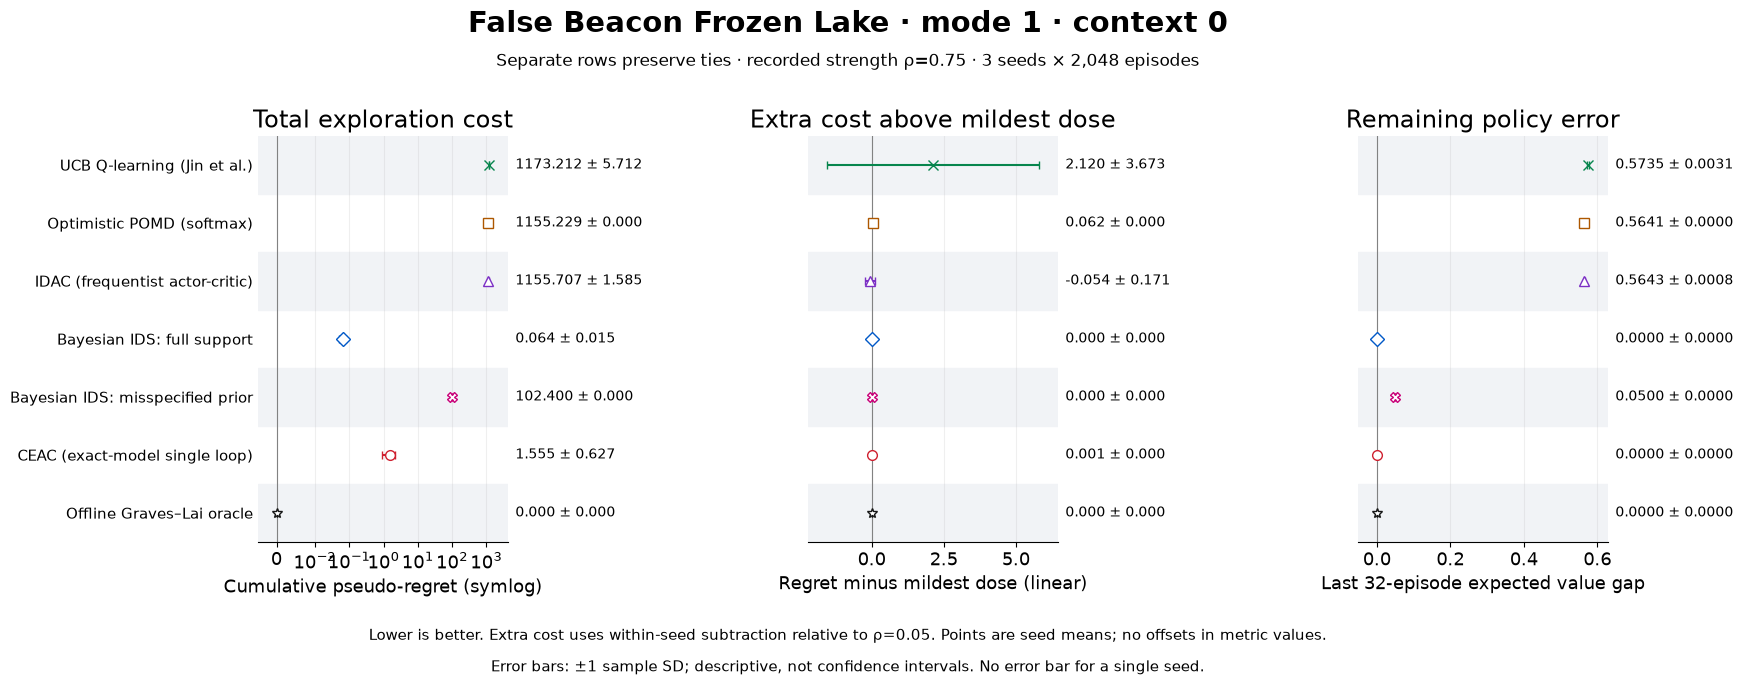

In [7]:
# Every setting must contain the complete seven-method slate before plotting.
from ceac.pathology_report import METHODS
expected_methods = set(METHODS)
for kind, context, mode in {key[:3] for key in groups}:
    observed = {key[3] for key in groups if key[:3] == (kind, context, mode)}
    assert observed == expected_methods, (kind, context, mode, observed)
for method, prior in (("ids", .5), ("ids_zero", 0.)):
    runs = [r for r in bundle["curves"] if r["result"]["method"] == method]
    assert len(runs) == 48
    assert all(r["manifest"]["configuration"]["ids_prior"] == prior for r in runs)
    print(f"{method}: {len(runs)} completed runs; initial mode-1 prior = {prior}")
for kind in ("deepsea", "frozenlake"):
    fig = draw_method_overlay(groups, kind, mode=MODE)
    plt.show()

for kind in ("deepsea", "frozenlake"):
    fig = draw_endpoint_comparison(bundle["pathology_statistics"], kind, mode=MODE)
    plt.show()


## 7. Increase physical pathology while keeping the task fixed

$$P_{m,\rho}(\cdot\mid s,a_N)
=(1-\rho)P_{\mathrm{pass}}(\cdot\mid s,a_N)+\rho P_{\mathrm{divert}}(\cdot\mid s,a_N).$$

The sweep uses $\rho=0.05,0.25,0.50,0.75$. Both branches are mode independent. Interior probabilities preserve an identical reachable state/action domain. Geometry, horizon, the four-symbol alphabet, optimal values, useful-route values, reward range and probe KL are checked across settings before training.

- **Undertow:** a nuisance move loses rightward progress with probability $\rho$; otherwise it advances.
- **False Beacon:** the first reed visit causes a forced dwell with probability $\rho$. It consumes one physical step. The observable state records pending/completed dwell, and the intended route resumes afterward.

The introductory route maps illustrate the geometry and deterministic nuisance behavior, not a sampled training curve. The new sweep changes physical diversion probability, **not symbol diversity**.

Following STEERING, each of the seven methods has its own panel, including both Bayesian priors: **x = training episode, y = cumulative pseudo-regret, color = physical strength**. All panels share a **symlog** y scale, linear within ±0.01; this keeps low-regret methods visible alongside costs above 1,000:

$$R_T=\sum_{t=1}^{T}\big[J_m^\star-J_m(\pi_t)\big].$$

The evaluator computes regret against the true-mode optimal value; the executed oracle allocation is not the reference. Coincident curves remain coincident. Stronger harm need not defeat a policy that learns to avoid it.

The additional-cost panels subtract the mildest-strength curve **within each seed before computing the SD**. Negative values mean lower measured regret than at mild strength; they are not clipped away.


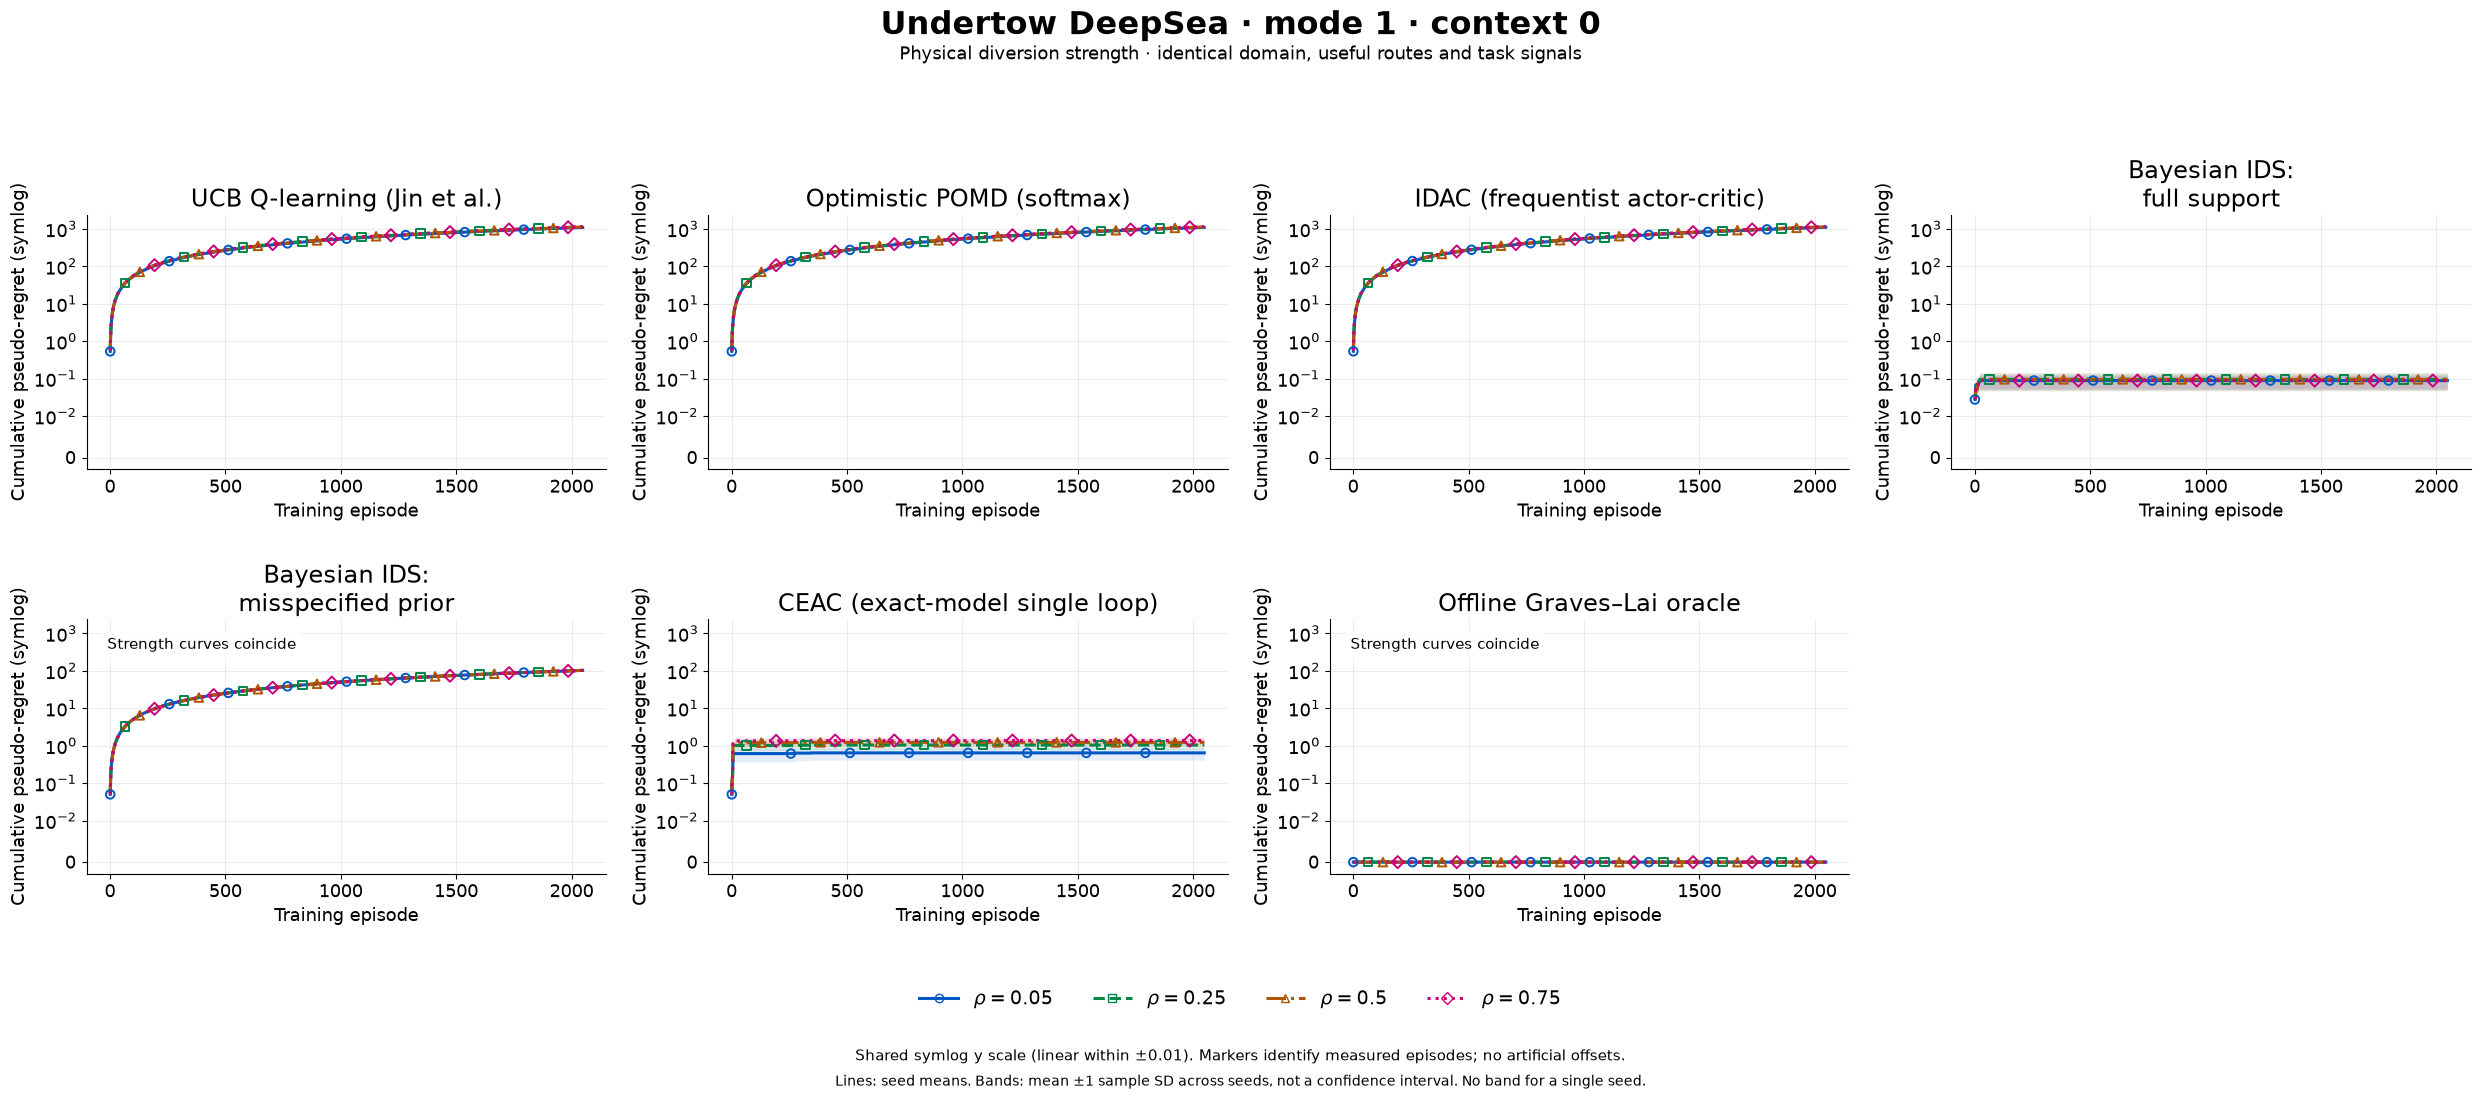

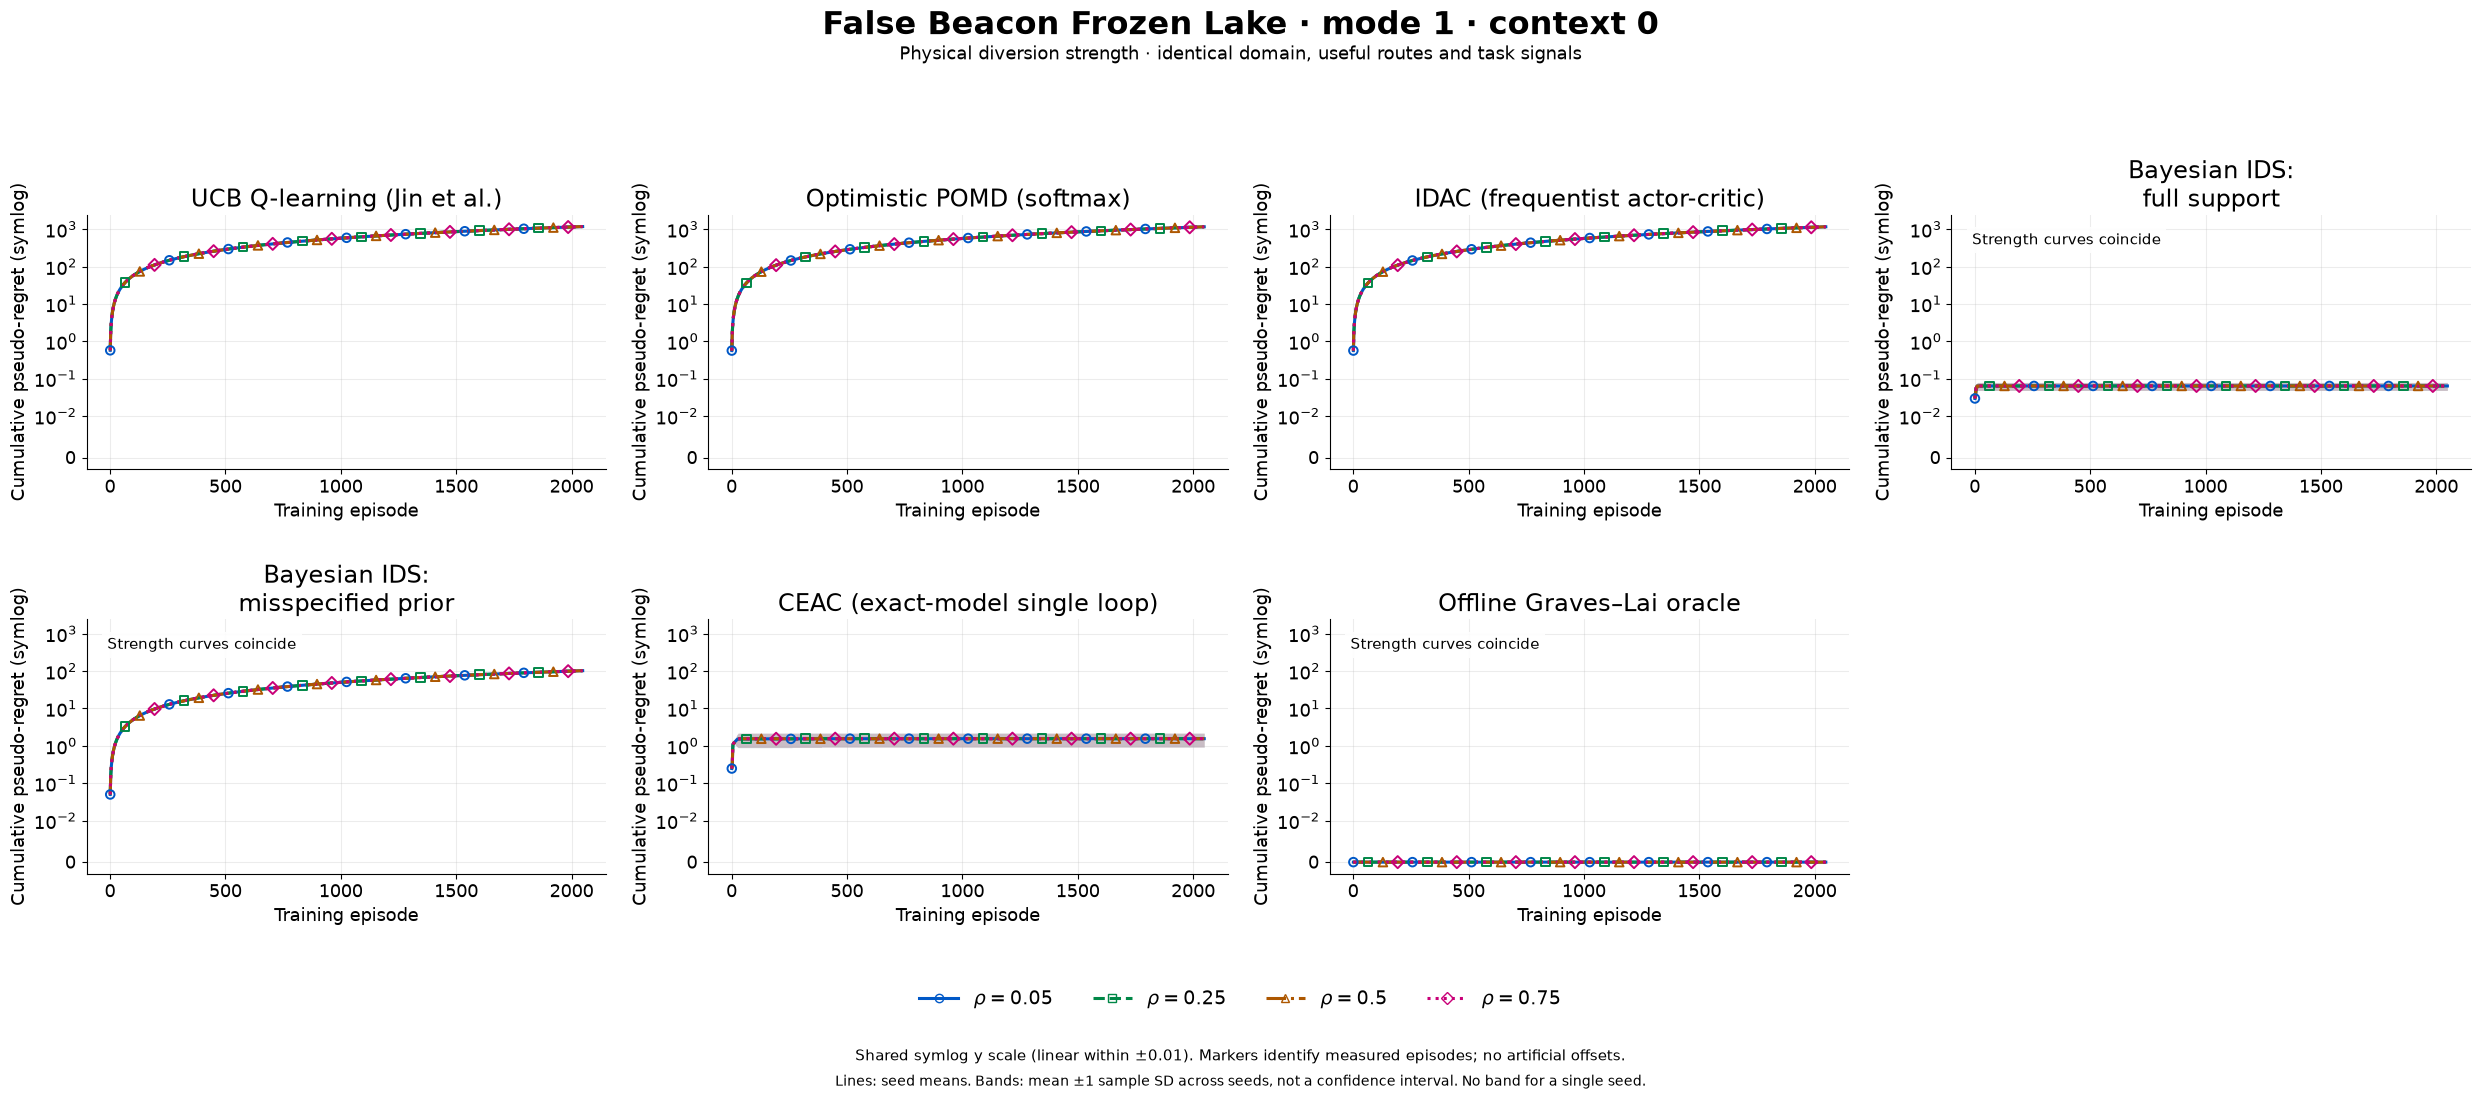

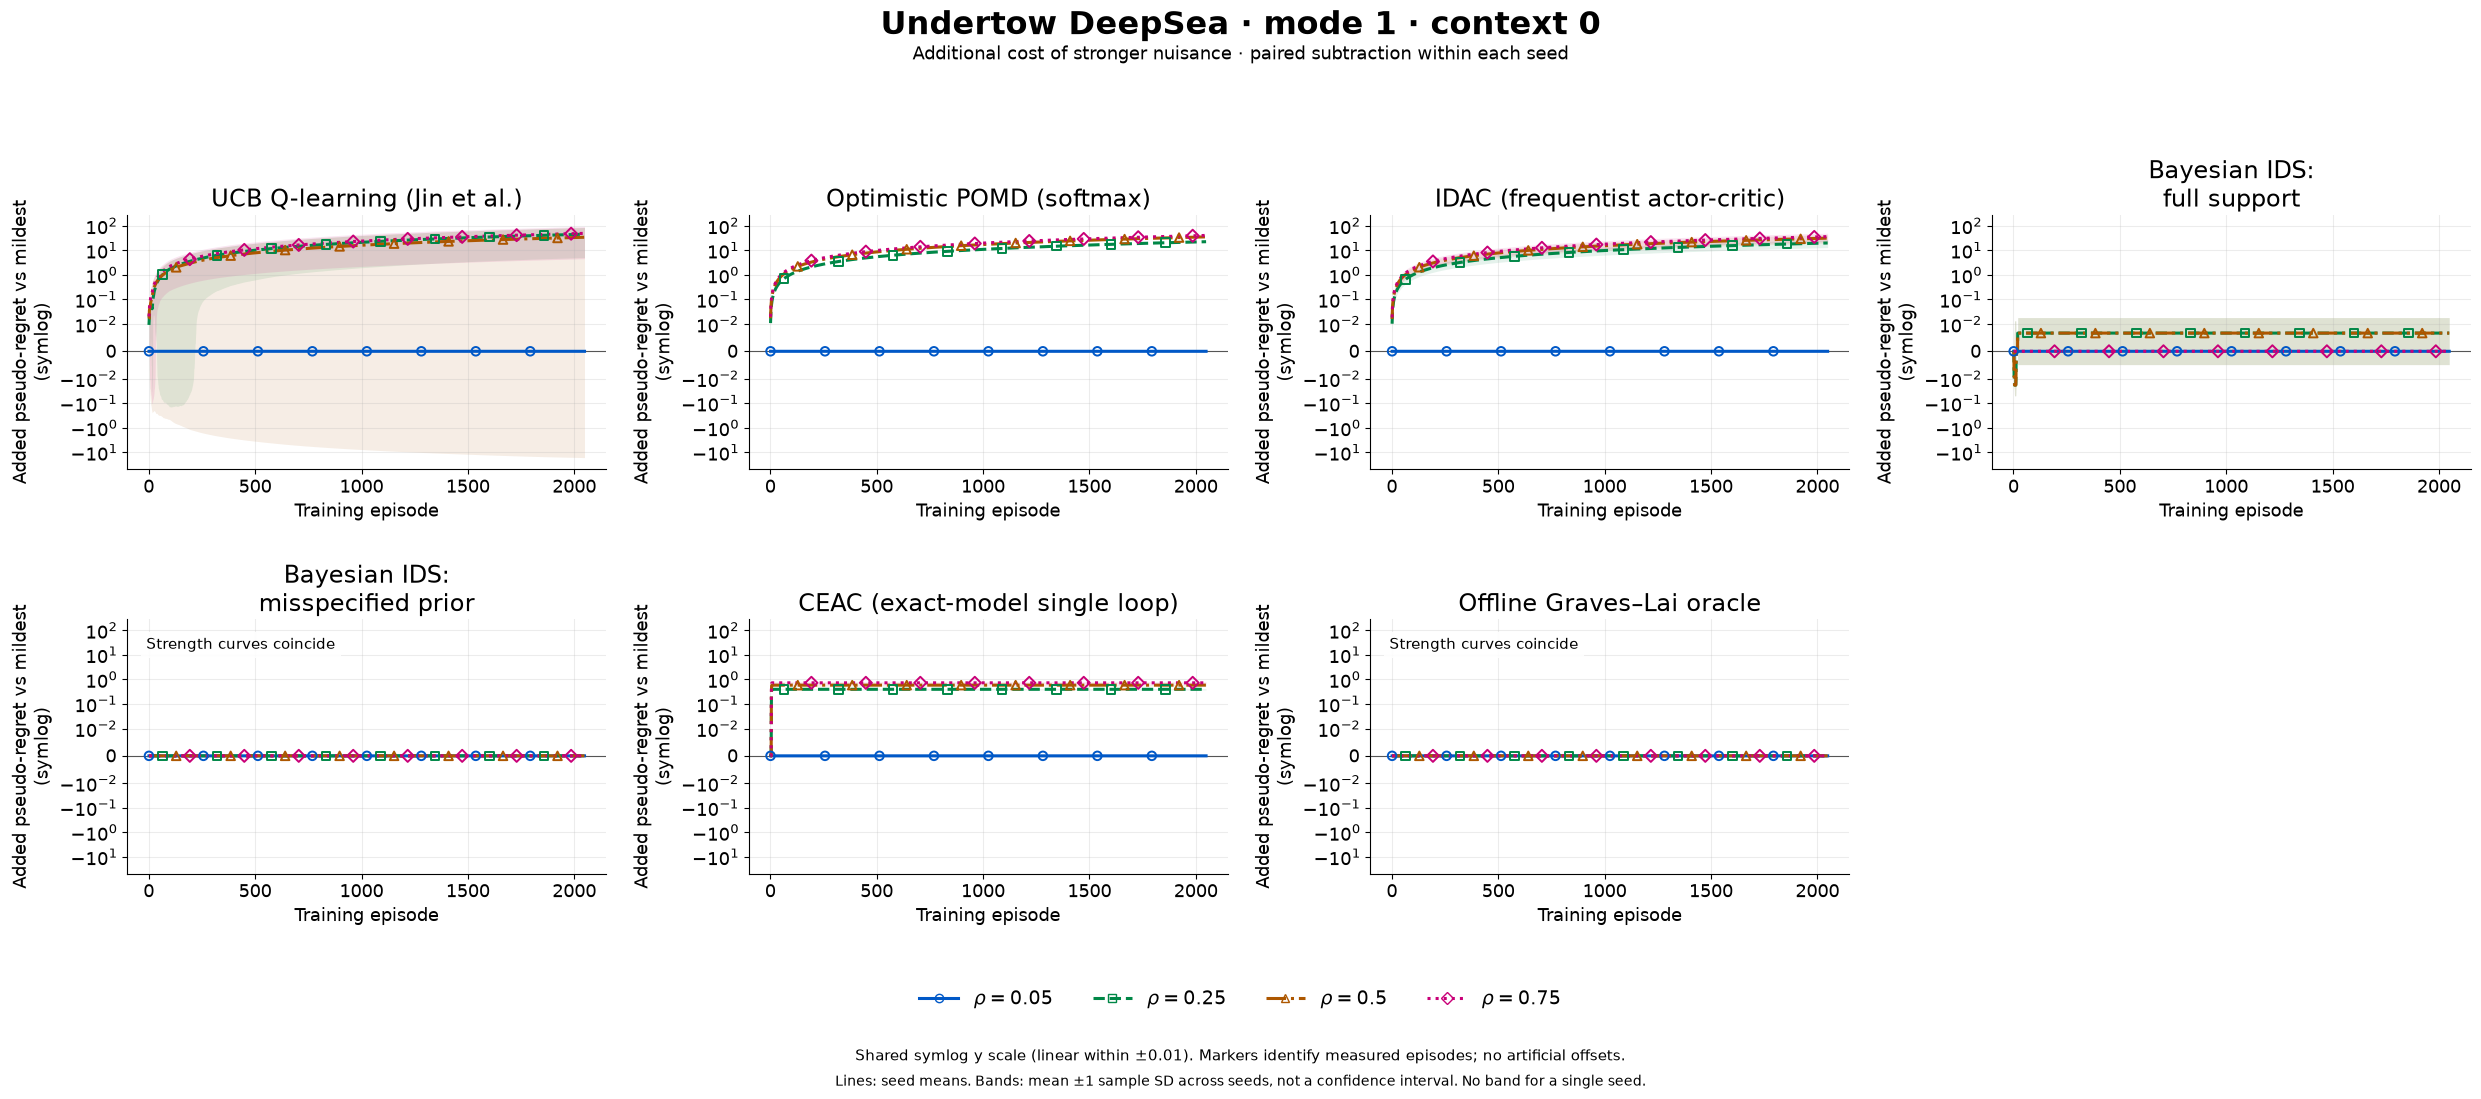

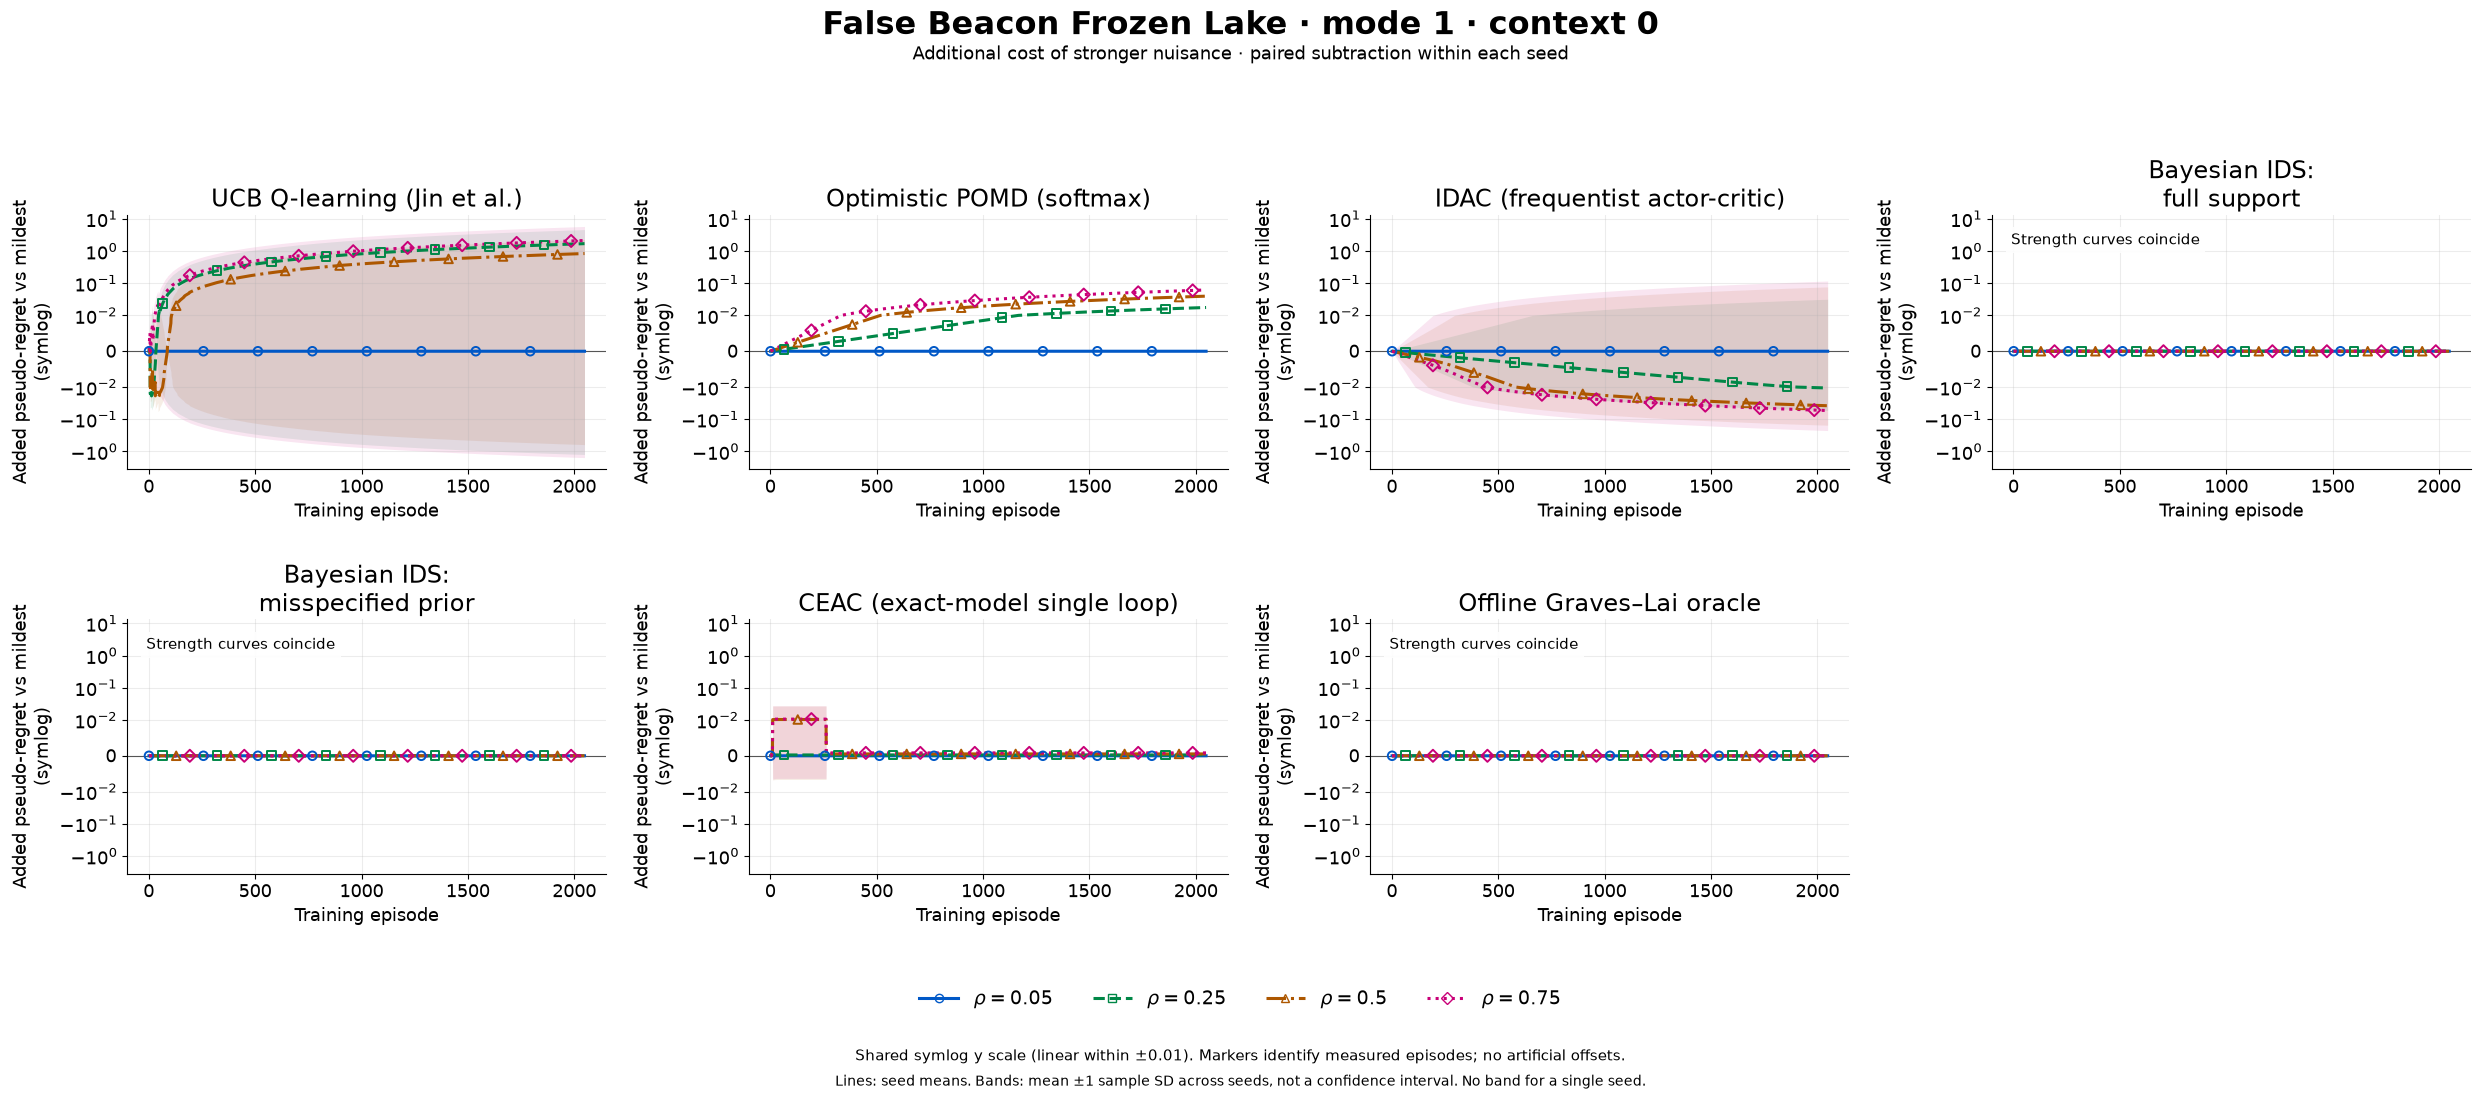

In [8]:
for kind in ("deepsea", "frozenlake"):
    fig = draw_strength_learning(groups, kind, mode=MODE)
    plt.show()

# Subtract the mildest-strength curve within each seed before computing SD.
for kind in ("deepsea", "frozenlake"):
    fig = draw_strength_learning(groups, kind, mode=MODE, incremental=True)
    plt.show()


### What actually went wrong?

The diagnostics distinguish failure to reach a rewarding terminal state, residual value gap, physical nuisance exposure, and lack of useful evidence. A plateau already present at mild strength cannot be attributed entirely to increasing pathology.

The flags are descriptive: POMD_BONUS_SATURATION means all optimistic costs were zero in at least 90% of episodes; PHYSICAL_NUISANCE_EXPOSURE records lost progress/dwell; FINITE_BUDGET_VALUE_GAP means the final 32-episode mean value gap exceeds 0.01. They are not causal ablations or asymptotic failure claims. Seed-level data and paired strong-minus-mild regret are exported automatically in pathology_statistics.json.


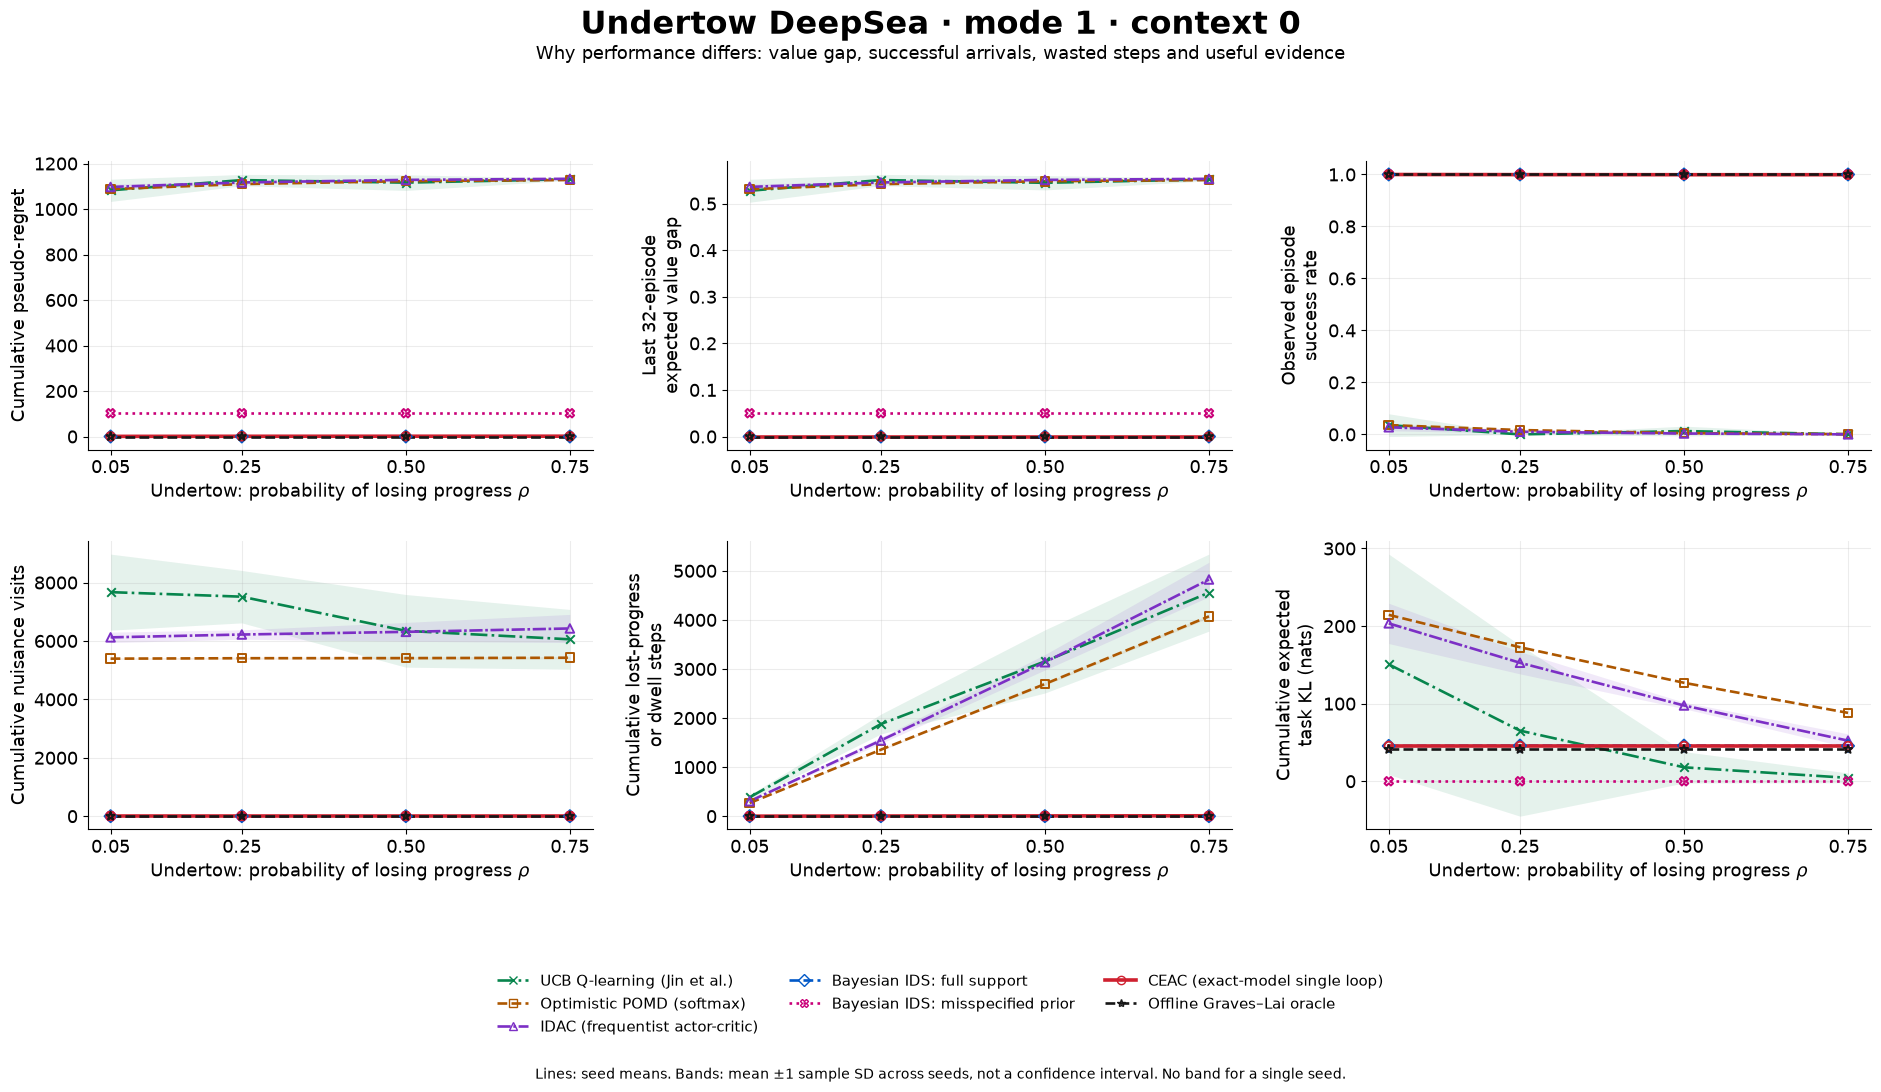

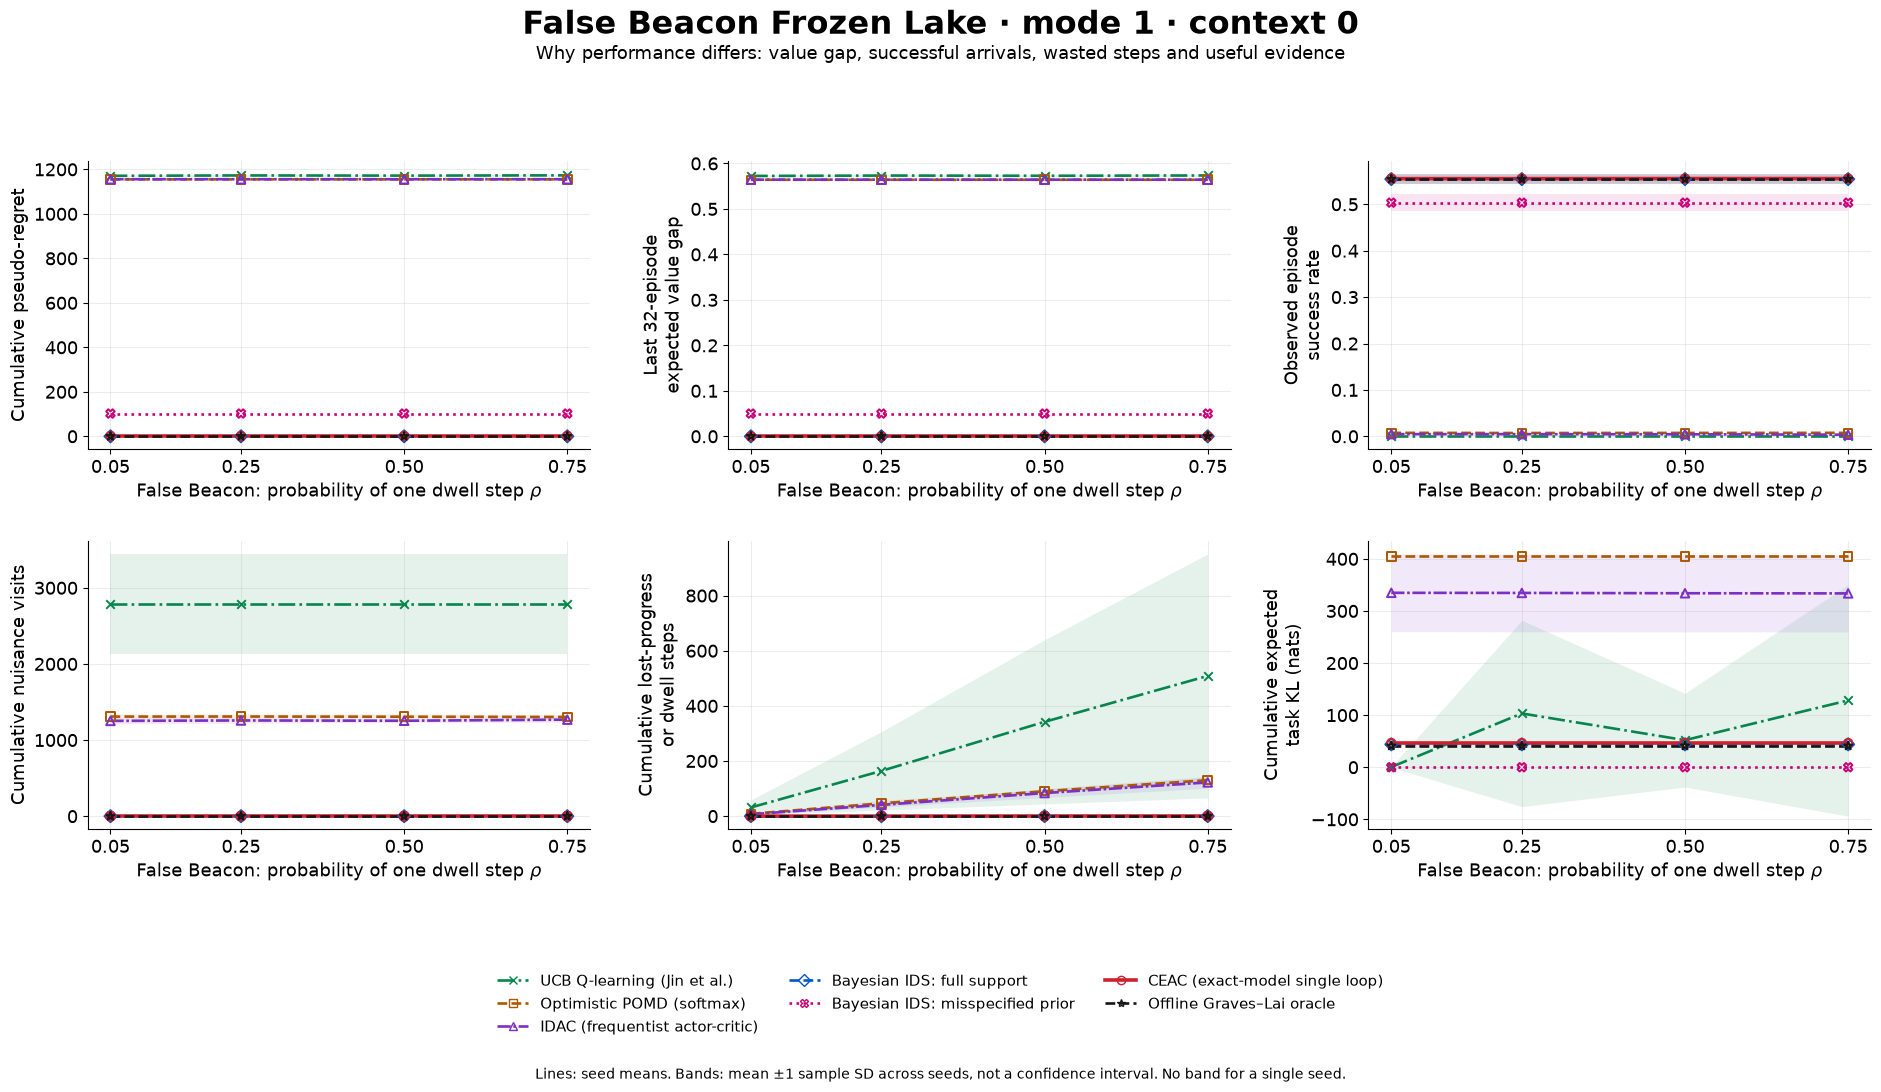

deepsea ucb_q strong-minus-mild regret: 48.740 ± 44.195 SD; ['FINITE_BUDGET_VALUE_GAP', 'PHYSICAL_NUISANCE_EXPOSURE']
frozenlake ucb_q strong-minus-mild regret: 2.120 ± 3.673 SD; ['FINITE_BUDGET_VALUE_GAP', 'PHYSICAL_NUISANCE_EXPOSURE']
deepsea pomd strong-minus-mild regret: 40.141 ± 0.000 SD; ['FINITE_BUDGET_VALUE_GAP', 'PHYSICAL_NUISANCE_EXPOSURE', 'POMD_BONUS_SATURATION']
frozenlake pomd strong-minus-mild regret: 0.062 ± 0.000 SD; ['FINITE_BUDGET_VALUE_GAP', 'PHYSICAL_NUISANCE_EXPOSURE', 'POMD_BONUS_SATURATION']
deepsea idac strong-minus-mild regret: 35.937 ± 13.519 SD; ['FINITE_BUDGET_VALUE_GAP', 'PHYSICAL_NUISANCE_EXPOSURE']
frozenlake idac strong-minus-mild regret: -0.054 ± 0.171 SD; ['FINITE_BUDGET_VALUE_GAP', 'PHYSICAL_NUISANCE_EXPOSURE']
deepsea ids strong-minus-mild regret: 0.000 ± 0.000 SD; ['no flagged gap']
frozenlake ids strong-minus-mild regret: 0.000 ± 0.000 SD; ['no flagged gap']
deepsea ids_zero strong-minus-mild regret: 0.000 ± 0.000 SD; ['FINITE_BUDGET_VALUE_GAP', '

In [9]:
for kind in ("deepsea", "frozenlake"):
    fig = draw_strength_diagnostics(bundle["pathology_statistics"], kind, mode=MODE)
    plt.show()
for method in METHODS:
    rows = [r for r in bundle["pathology_statistics"]
            if r["mode"] == MODE and r["rho"] == .75 and r["method"] == method]
    for kind in ("deepsea", "frozenlake"):
        subset = [r for r in rows if r["environment"] == kind]
        delta = np.array([r["added_regret"] for r in subset])
        flags = sorted({f for r in subset for f in r["diagnostic_flags"]})
        print(kind, method, "strong-minus-mild regret:",
              f"{delta.mean():.3f} ± {delta.std(ddof=1):.3f} SD;", flags or ["no flagged gap"])


## 8. Bayesian support exclusion is a separate failure mechanism

Both Bayesian treatments are in the main overlays and strength panels above. The `ids` arm uses $p_0=(0.5,0.5)$; the `ids_zero` arm uses $p_0=(1,0)$, deliberately assigning mode 1 zero prior probability:

$$p_t(1)=\frac{p_0(1)L_t(1)}{p_0(0)L_t(0)+p_0(1)L_t(1)}=0.$$

In mode 1 it never requests the diagnostic. The old route has true gap 0.05, giving exactly $2,048\times0.05=102.4$ cumulative pseudo-regret at every diversion strength. This is a failure of excluded prior support, not evidence that increasing physical nuisance defeats full-support Bayesian IDS. A small positive prior is a different treatment.

In mode 0 the restricted prior contains the true model, providing a negative control. The following focused overlays supplement the full seven-method slate and clarify these Bayesian assumptions. CEAC still has both candidate models, so they do not establish discovery outside its declared family.


Verified all 96 Bayesian runs: priors, posterior support, and the exact exclusion-regret prediction.


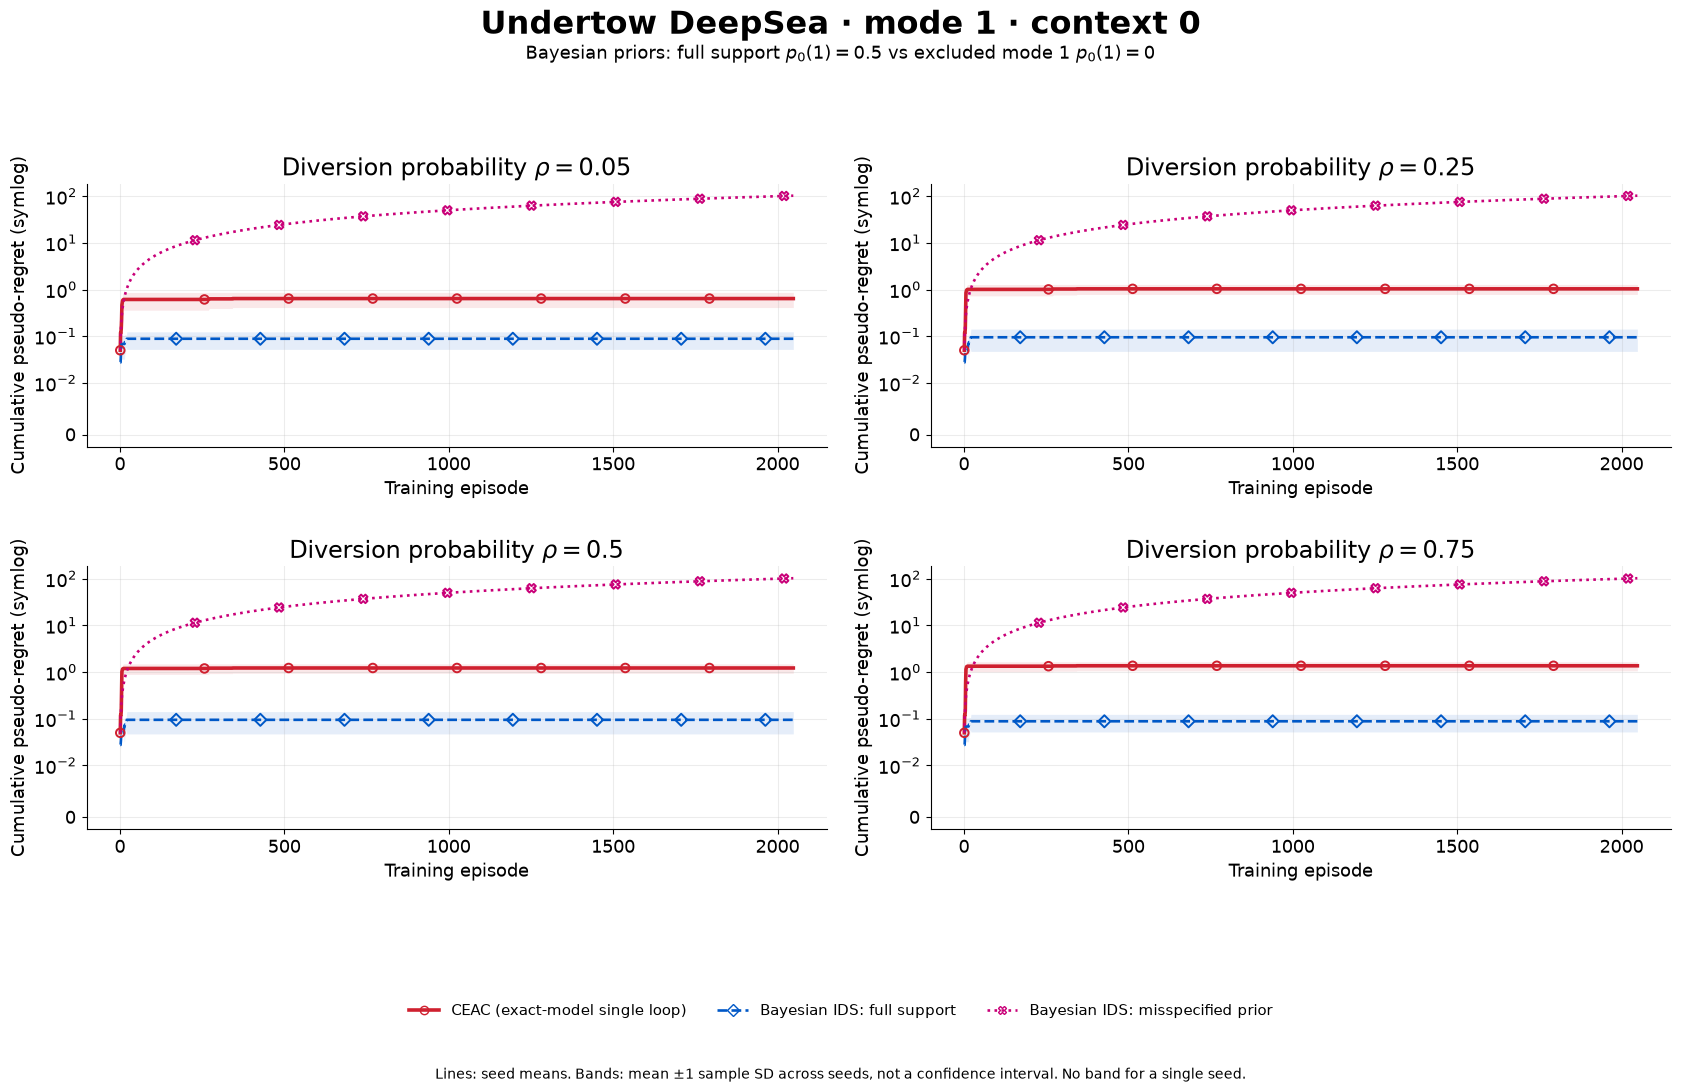

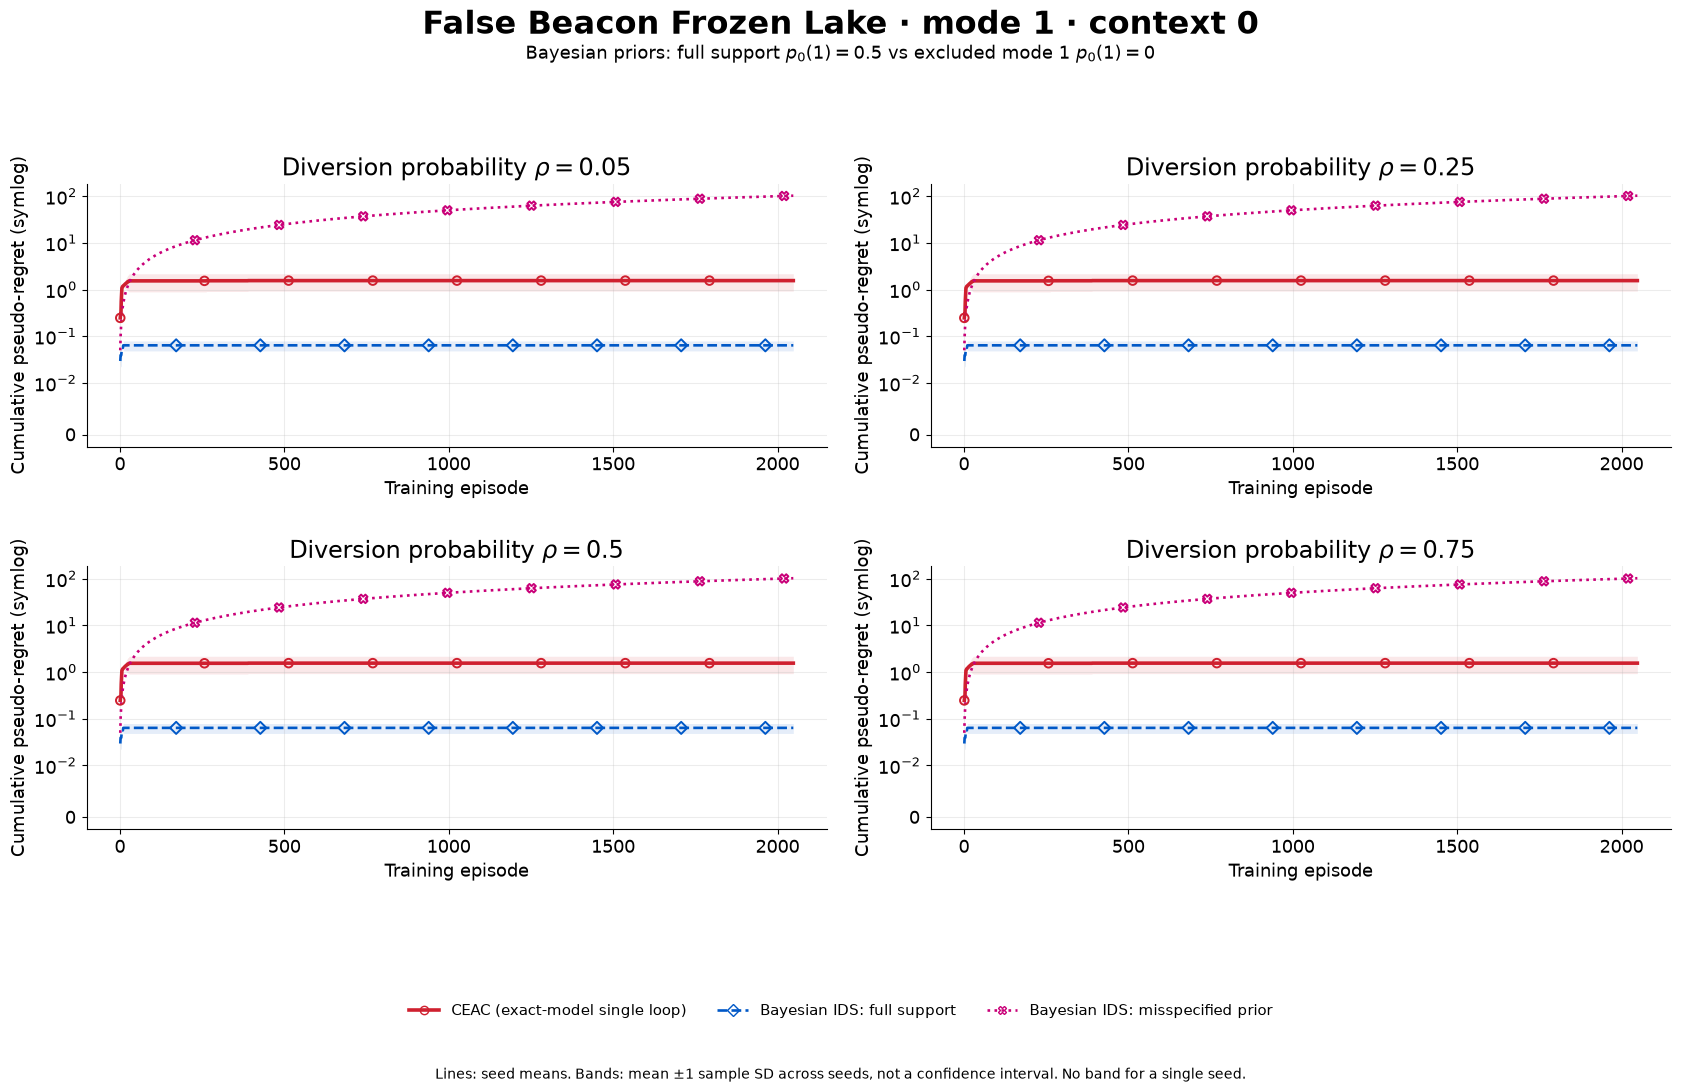

In [10]:
bayesian = [r for r in bundle["curves"] if r["result"]["method"] in ("ids", "ids_zero")]
assert len(bayesian) == 96
for run in bayesian:
    result, metrics = run["result"], run["metrics"]
    posterior = np.array([m["diagnostics"]["posterior"][1] for m in metrics])
    if result["method"] == "ids_zero":
        np.testing.assert_array_equal(posterior, 0)
        assert all(m["diagnostics"]["prior_support"] == [True, False] for m in metrics)
        gap = .05 if result["true_mode"] == 1 else 0.
        np.testing.assert_allclose([m["cumulative_pseudo_regret"] for m in metrics],
                                   gap * np.arange(1, result["episodes"]+1), atol=1e-8, rtol=0)
        assert metrics[-1]["cumulative_diagnostic_visits"] == 0
    else:
        assert np.all(np.isfinite(posterior)) and np.all(posterior > 0)
        assert all(m["diagnostics"]["prior_support"] == [True, True] for m in metrics)
print("Verified all 96 Bayesian runs: priors, posterior support, and the exact exclusion-regret prediction.")
for kind in ("deepsea", "frozenlake"):
    fig = draw_method_overlay(groups, kind, mode=MODE, prior=True)
    plt.show()


## 9. What “CEAC” and “certified deployment” mean here

This is the maintained **single episode-loop, exact-model specialization** of CEAC. Its behavior scheduler serves statistical requests and design debts first. On free episodes, it uses a reward-only policy if

$$\max_{m\in\mathcal C_t}\big[J_m^\star-J_m(\widehat\pi_t)\big]\le10^{-10}.$$

Here $\mathcal C_t$ is inferred from trajectory likelihoods. The guarantee applies on the model-confidence event within the declared family. It does not certify an arbitrary misspecified environment.

| | CEAC in these runs | Offline Graves–Lai oracle |
|---|---|---|
| Realized mode | Unknown; learned from trajectories | Supplied from the outset |
| Design | Refreshed using accumulated evidence | Normalized allocation computed once |
| Free-episode execution | Confidence-set-certified reward-only response | True-model optimal policy |
| Planning | Exact candidate-model evaluation and separation | Same access plus true mode |

The oracle's curve includes its scheduled experiments; it is not a finite-time lower bound. Exact separation and deployment planning are explicit implementation choices documented in the ledgers. **The curves do not isolate a causal benefit from the learned TD evidence critic.**

In [11]:
history = [r for r in bundle["history_audits"] if r["method"] == "ceac"]
assert len(history) == sum(r["method"] == "ceac" for r in bundle["endpoints"])
zero = sum(r["actor_updates"] == 0 for r in history)
admitted = sum(r["actor_admissions"] for r in history)
print(f"CEAC audit: {zero}/{len(history)} runs made zero actor/critic updates.")
print(f"Learned actor proposals admitted: {admitted}.")
print("Cumulative likelihood estimates, confidence sets and policy credits were reconstructed from saved trajectories.")
print("Mechanism attribution requires a learned-estimator experiment with matched ablations.")

CEAC audit: 36/48 runs made zero actor/critic updates.
Learned actor proposals admitted: 0.
Cumulative likelihood estimates, confidence sets and policy credits were reconstructed from saved trajectories.
Mechanism attribution requires a learned-estimator experiment with matched ablations.


## 10. One runner, one renderer, one notebook evidence interface

The default notebook reads the completed sweep and launches no training. The cell below prints its launch command with a fresh output name. After training, the standard report includes all method overlays, strength traces and failure diagnostics automatically:

    python -m ceac.report --input runs/my_pathology_strength --pdf
    python scripts/export_walkthrough.py --study runs/my_pathology_strength
    python scripts/verify_notebook.py --write

The exporter verifies complete runs, source archives and report artifact hashes. It replaces the maintained portable notebook evidence with that explicitly selected study. Raw historical experiments remain in their original folders; incompatible runtimes are never pooled.

References and adaptations: [comparator provenance](../docs/comparator_provenance.md), [physical-strength protocol](../docs/pathology_sweep.md), and [CEAC implementation ledger](../audits/ceac_v90_corrections_20261110.md).


In [12]:
import shlex
command = ["python", "-m", "ceac.run", "--output", "runs/my_pathology_strength",
           "--benchmarks", "pathology_rho005", "pathology_rho025", "pathology_rho050", "pathology_rho075",
           "--environments", "deepsea", "frozenlake",
           "--methods", "ceac", "oracle", "ids", "idac", "ucb_q", "pomd", "ids_zero",
           "--modes", "0", "1", "--seeds", "0", "1", "2", "--episodes", "2048", "--workers", "4"]
print(shlex.join(command))
print("Notebook complete. No training was launched.")


python -m ceac.run --output runs/my_pathology_strength --benchmarks pathology_rho005 pathology_rho025 pathology_rho050 pathology_rho075 --environments deepsea frozenlake --methods ceac oracle ids idac ucb_q pomd ids_zero --modes 0 1 --seeds 0 1 2 --episodes 2048 --workers 4
Notebook complete. No training was launched.


## 11. Prepared follow-up: physical False Beacon breadth

This is a **separate prepared experiment**, not a relabeling of the completed activation-probability sweep above. It adds 0, 1, 2, 4 or 8 traversable cells in a chamber behind the uninformative shallow buoy. Only one gate connects it to the original shoreline, so widening the chamber does not create a useful shortcut.

![Prepared physical breadth](assets/beacon_breadth_design.png)

The exact preflight verifies fixed rewards, 16-step horizon, four primitive actions, six seed routes, useful-route values/KL, optimal returns and oracle allocation costs. Every added chamber transition has zero task KL. **The reachable domain grows**; the prescribed domain-dependent optimism bonuses may therefore change too.

| Additional physical chamber cells | Reachable tabular states (including time and signals) |
|---:|---:|
| 0 | 3733 |
| 1 | 3813 |
| 2 | 3893 |
| 4 | 4023 |
| 8 | 4223 |

The full registered slate is **350 cells**: five breadths, two modes, five seeds, seven methods, and 8,192 episodes. It has not been launched. Both Bayesian priors remain separate; full-support IDS is not expected to lose support merely because mode-independent chamber cells are added.

A **28-cell / 896-episode integration smoke** has passed with all seven methods and both modes at B=0 and B=8. It validates execution, chamber-exposure logging and report rendering, not a performance conclusion. The report distinguishes total regret, added regret relative to B=0, paired CEAC advantage, chamber steps, distinct chamber cells and useful task KL. A baseline plateau or POMD bonus saturation must not be presented as a breadth effect.

From the repository root, inspect the commands without launching training:

    .venv/bin/python scripts/run_beacon_breadth.py --stage plan

[Protocol and full launch instructions](../docs/false_beacon_breadth.md) · [Registered configuration](../experiments/false_beacon_breadth.json) · [Exact preflight](../audits/beacon_breadth_preflight_20261111/preflight.json) · [Validation ledger](../audits/beacon_breadth_validation_20261111.json)

The completed sweep displayed above retains its original evidence export. A breadth study uses its own output directory and the standard report renderer; it is not pooled into the older activation sweep.
